In [1]:
## 1 : environnement + connexion au tracking server ---
from pathlib import Path
import os

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
for d in (RAW_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATA_DIR, RAW_DIR

(PosixPath('./data'),
 PosixPath('./data/raw'))

In [2]:
### --- Connexion MLflow ---
%env MLFLOW_TRACKING_URI=http://127.0.0.1:5000

import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("home-credit-scoring")

client = mlflow.MlflowClient()
print("Tracking URI :", mlflow.get_tracking_uri())
print("Expérience   :", client.get_experiment_by_name("home-credit-scoring"))

env: MLFLOW_TRACKING_URI=http://127.0.0.1:5000


./.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/24 18:14:02 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at ./.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Tracking URI : http://127.0.0.1:5000


Expérience   : <Experiment: artifact_location='./mlflow-artifacts/1', creation_time=1792697169637, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792697169637, lifecycle_stage='active', name='home-credit-scoring', tags={}, trace_location=None, workspace='default'>


In [3]:
## 2 : téléchargement (≈ 690 MB, une seule fois) ---
import urllib.request

URL = (
    "https://s3-eu-west-1.amazonaws.com/static.oc-static.com/prod/courses/files/"
    "Parcours_data_scientist/Projet+-+Impl%C3%A9menter+un+mod%C3%A8le+de+scoring/"
    "Projet+Mise+en+prod+-+home-credit-default-risk.zip"
)
ZIP_PATH = RAW_DIR / "home-credit-default-risk.zip"

if not ZIP_PATH.exists():
    print("Téléchargement en cours… (~690 MB, quelques minutes)")
    urllib.request.urlretrieve(URL, ZIP_PATH)
    print("OK :", ZIP_PATH.stat().st_size / 1e6, "MB")
else:
    print("Déjà téléchargé :", ZIP_PATH)

Déjà téléchargé : ./data/raw/home-credit-default-risk.zip


In [4]:
## 3 : extraction sélective ---
import zipfile

WANTED = [
    "application_train.csv",
    "application_test.csv",
    "HomeCredit_columns_description.csv",
    # Décommente plus tard, pour les agrégats historiques :
    # "bureau.csv", "bureau_balance.csv", "previous_application.csv",
]

with zipfile.ZipFile(ZIP_PATH) as zf:
    available = set(zf.namelist())
    for name in WANTED:
        target = RAW_DIR / name
        if target.exists():
            print(f"déjà là : {name}")
            continue
        if name not in available:
            print(f"ABSENT du zip : {name}")
            continue
        zf.extract(name, RAW_DIR)
        print(f"extrait : {name} ({target.stat().st_size / 1e6:.0f} MB)")

déjà là : application_train.csv
déjà là : application_test.csv
déjà là : HomeCredit_columns_description.csv


In [5]:
## 4 : chargement ---
import pandas as pd
import numpy as np

app_train = pd.read_csv(RAW_DIR / "application_train.csv")
app_test = pd.read_csv(RAW_DIR / "application_test.csv")

print("train :", app_train.shape)
print("test  :", app_test.shape)
print("\nTaux de défaut :", f"{app_train['TARGET'].mean():.4%}")
print("\nColonnes à valeurs mixtes/non déclarées :")
for col in app_train.columns:
    if app_train[col].dtype == object:
        print(f"  {col:40s} {app_train[col].nunique():4d} modalités | ex: {app_train[col].unique()[:3]}")

train : (307511, 122)
test  : (48744, 121)

Taux de défaut : 8.0729%

Colonnes à valeurs mixtes/non déclarées :


## 5 : EDA exploratoire (pandas) ---
Objectif : comprendre la structure, la qualité et la signalétique des données avant toute modélisation.

In [6]:
### 5.1 — aperçu général
print('=== Dimensions ===')
print('train :', app_train.shape, '| test :', app_test.shape)
print('colonnes en commun :', len(set(app_train.columns) & set(app_test.columns)))
print('colonnes train-only :', sorted(set(app_train.columns) - set(app_test.columns)))

print('\n=== Types de variables ===')
print(app_train.dtypes.value_counts().to_string())

num_cols = app_train.select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in app_train.columns if c not in num_cols]
print(f'\n{len(num_cols)} numériques, {len(cat_cols)} catégorielles')

print('\n=== Doublons ===')
print('lignes dupliquées        :', app_train.duplicated().sum())
print('SK_ID_CURR dupliqués     :', app_train['SK_ID_CURR'].duplicated().sum())

print('\n=== Constantes (une seule valeur) ===')
constants = [c for c in app_train.columns if app_train[c].nunique(dropna=False) == 1]
print(constants if constants else 'aucune')
print(f'\n{len(constants)} colonnes sans pouvoir prédictif -> à supprimer')

=== Dimensions ===
train : (307511, 122) | test : (48744, 121)
colonnes en commun : 121
colonnes train-only : ['TARGET']

=== Types de variables ===
float64    65
int64      41
str        16

106 numériques, 16 catégorielles

=== Doublons ===


lignes dupliquées        : 0
SK_ID_CURR dupliqués     : 0

=== Constantes (une seule valeur) ===


aucune

0 colonnes sans pouvoir prédictif -> à supprimer


In [7]:
### 5.2 — statistiques descriptives des variables numériques
pd.set_option('display.width', 200)

desc = app_train[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc['skew'] = app_train[num_cols].skew()

print('=== 15 variables les plus asymétriques ===')
desc.sort_values('skew', key=lambda s: s.abs(), ascending=False).head(15)

=== 15 variables les plus asymétriques ===


,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
FLAG_MOBIL,307511.0,0.999997,0.001803,0.0,1.0,1.0,1.0,1.0,1.0,1.0,-554.536744
FLAG_DOCUMENT_12,307511.0,0.000007,0.002550,0.0,0.0,0.0,0.0,0.0,0.0,1.0,392.114779
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,45000.0,112500.0,147150.0,202500.0,472500.0,117000000.0,391.559654
FLAG_DOCUMENT_10,307511.0,0.000023,0.004771,0.0,0.0,0.0,0.0,0.0,0.0,1.0,209.589054
FLAG_DOCUMENT_2,307511.0,0.000042,0.006502,0.0,0.0,0.0,0.0,0.0,0.0,1.0,153.791817
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,0.0,2.0,261.0,134.365776
FLAG_DOCUMENT_4,307511.0,0.000081,0.009016,0.0,0.0,0.0,0.0,0.0,0.0,1.0,110.894364
FLAG_DOCUMENT_7,307511.0,0.000192,0.013850,0.0,0.0,0.0,0.0,0.0,0.0,1.0,72.174108
FLAG_DOCUMENT_17,307511.0,0.000267,0.016327,0.0,0.0,0.0,0.0,0.0,0.0,1.0,61.214140
FLAG_DOCUMENT_21,307511.0,0.000335,0.018299,0.0,0.0,0.0,0.0,0.0,0.0,1.0,54.612939


In [8]:
### 5.3 — valeurs manquantes
n_missing = app_train.isna().sum()
n_missing = n_missing[n_missing > 0].sort_values(ascending=False)

missing_df = pd.DataFrame({
    'nb_manquant': n_missing,
    'pct_manquant': (n_missing / len(app_train) * 100).round(2),
})

print(f'{len(missing_df)} colonnes contiennent des NaN (sur {app_train.shape[1]})')
print(f"dont {int((missing_df['pct_manquant'] > 50).sum())} avec plus de 50 % de manquants")
print(f"dont {int((missing_df['pct_manquant'] > 10).sum())} avec plus de 10 % de manquants\n")
missing_df.head(20)

67 colonnes contiennent des NaN (sur 122)
dont 41 avec plus de 50 % de manquants
dont 57 avec plus de 10 % de manquants



,nb_manquant,pct_manquant
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


Distribution de TARGET :
TARGET
0    282686
1     24825
Taux de défaut : 8.07%


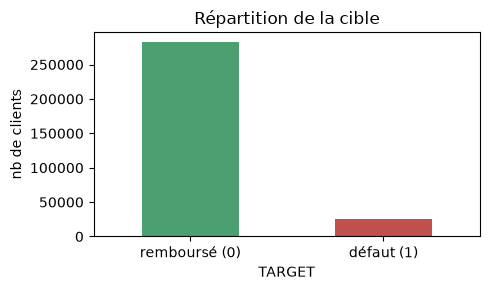

In [9]:
### 5.4 — la cible TARGET
import matplotlib.pyplot as plt

print('Distribution de TARGET :')
print(app_train['TARGET'].value_counts().sort_index().to_string())
print('Taux de défaut :', f"{app_train['TARGET'].mean():.2%}")

fig, ax = plt.subplots(figsize=(5, 3))
app_train['TARGET'].value_counts().sort_index().plot.bar(
    ax=ax, color=['#4C9F70', '#C0504D'], legend=False
)
ax.set_xticklabels(['remboursé (0)', 'défaut (1)'], rotation=0)
ax.set_ylabel('nb de clients')
ax.set_title('Répartition de la cible')
plt.tight_layout()
plt.show()

In [10]:
### 5.5 — taux de défaut par modalité des variables catégorielles


def taux_defaut_par(col):
    """Taux de défaut et effectif par modalité d'une variable catégorielle."""
    return (
        app_train.groupby(col, dropna=False)['TARGET']
        .agg(taux_defaut='mean', effectif='size')
        .sort_values('taux_defaut', ascending=False)
    )


for col in [
    'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
    'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'NAME_EDUCATION_TYPE',
]:
    print(f'\n=== {col} ===')
    print(taux_defaut_par(col))


=== NAME_CONTRACT_TYPE ===
                    taux_defaut  effectif
NAME_CONTRACT_TYPE                       
Cash loans             0.083459    278232
Revolving loans        0.054783     29279

=== CODE_GENDER ===
             taux_defaut  effectif
CODE_GENDER                       
M               0.101419    105059
F               0.069993    202448
XNA             0.000000         4

=== FLAG_OWN_CAR ===
              taux_defaut  effectif
FLAG_OWN_CAR                       
N                0.085002    202924
Y                0.072437    104587

=== FLAG_OWN_REALTY ===
                 taux_defaut  effectif
FLAG_OWN_REALTY                       
N                   0.083249     94199
Y                   0.079616    213312

=== NAME_INCOME_TYPE ===


                      taux_defaut  effectif
NAME_INCOME_TYPE                           
Maternity leave          0.400000         5
Unemployed               0.363636        22
Working                  0.095885    158774
Commercial associate     0.074843     71617
State servant            0.057550     21703
Pensioner                0.053864     55362
Businessman              0.000000        10
Student                  0.000000        18

=== NAME_FAMILY_STATUS ===
                      taux_defaut  effectif
NAME_FAMILY_STATUS                         
Civil marriage           0.099446     29775
Single / not married     0.098077     45444
Separated                0.081942     19770
Married                  0.075599    196432
Widow                    0.058242     16088
Unknown                  0.000000         2

=== NAME_HOUSING_TYPE ===
                     taux_defaut  effectif
NAME_HOUSING_TYPE                         
Rented apartment        0.123131      4881
With parents            

In [11]:
### 5.6 — variables temporelles (DAYS_*) : jours négatifs -> années
days_cols = [c for c in num_cols if c.startswith('DAYS_')]
print('colonnes DAYS_ :', days_cols)

days_years = (app_train[days_cols] / -365.25).describe(
    percentiles=[0.5, 0.9, 0.99, 0.999]
).T
display(days_years)

# Anomalie connue du dataset : sentinelle 365243 jours (= 1000 ans)
sentinel = app_train['DAYS_EMPLOYED'] == 365243
print(f"\nDAYS_EMPLOYED == 365243 (sentinelle '1000 ans') : {sentinel.sum()} clients ({sentinel.mean():.2%})")

colonnes DAYS_ : ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']


,count,mean,std,min,50%,90%,99%,99.9%,max
DAYS_BIRTH,307511.0,43.906900,11.947950,20.503765,43.121150,60.728268,66.855578,68.459959,69.073238
DAYS_EMPLOYED,307511.0,-174.716074,386.791969,-999.980835,3.321013,13.363450,29.828611,39.272964,49.040383
DAYS_REGISTRATION,307511.0,13.651253,9.645137,-0.000000,12.331280,27.192334,37.998631,45.182697,67.548255
DAYS_ID_PUBLISH,307511.0,8.197679,4.132650,-0.000000,8.908966,12.933607,14.913073,16.531143,19.704312
DAYS_LAST_PHONE_CHANGE,307510.0,2.636164,2.263678,-0.000000,2.072553,5.908282,8.621492,9.808326,11.750856



DAYS_EMPLOYED == 365243 (sentinelle '1000 ans') : 55374 clients (18.01%)


,count,mean,std,min,50%,90%,99%,99.9%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,147150.0,270000.0,472500.0,900000.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,513531.0,1133748.0,1854000.0,2517300.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,24903.0,45954.0,70006.5,110047.5,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,450000.0,1093500.0,1800000.0,2250000.0,4050000.0
AMT_REQ_CREDIT_BUREAU_HOUR,265992.0,0.006402,0.083849,0.0,0.0,0.0,0.0,1.0,4.0
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,1.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,1.0,2.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,1.0,4.0,12.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,1.0,2.0,4.0,261.0
AMT_REQ_CREDIT_BUREAU_YEAR,265992.0,1.899974,1.869295,0.0,1.0,4.0,8.0,9.0,25.0


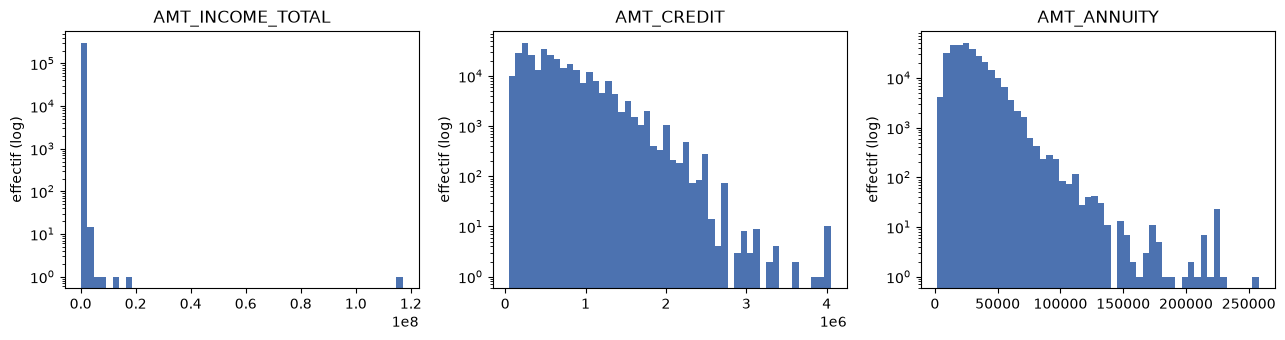

Revenus les plus élevés (outliers potentiels) :
12840     117000000.0
203693     18000090.0
246858     13500000.0
77768       9000000.0
131127      6750000.0


In [12]:
### 5.7 — montants (AMT_*) : distributions très asymétriques
amt_cols = [c for c in num_cols if c.startswith('AMT_')]
display(app_train[amt_cols].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).T)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY']):
    ax.hist(app_train[col].dropna(), bins=50, color='#4C72B0')
    ax.set_title(col)
    ax.set_yscale('log')
    ax.set_ylabel('effectif (log)')
plt.tight_layout()
plt.show()

print('Revenus les plus élevés (outliers potentiels) :')
print(app_train['AMT_INCOME_TOTAL'].nlargest(5).to_string())

=== 10 corrélations les plus négatives ===
EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.155317
DAYS_EMPLOYED                -0.044932
FLOORSMAX_AVG                -0.044003
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_MODE               -0.043226
AMT_GOODS_PRICE              -0.039645
REGION_POPULATION_RELATIVE   -0.037227
ELEVATORS_AVG                -0.034199

=== 10 corrélations les plus positives ===
DAYS_REGISTRATION              0.041975
FLAG_DOCUMENT_3                0.044346
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239


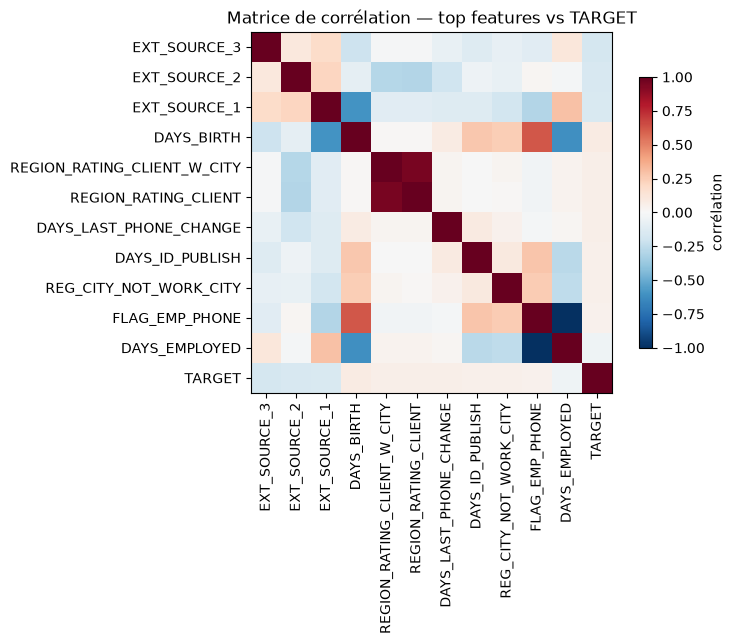

In [13]:
### 5.8 — corrélations avec la cible
corr_target = app_train[num_cols].corr()['TARGET'].drop('TARGET').sort_values()

print('=== 10 corrélations les plus négatives ===')
print(corr_target.head(10).to_string())
print('\n=== 10 corrélations les plus positives ===')
print(corr_target.tail(10).to_string())

top_features = corr_target.abs().nlargest(11).index.tolist() + ['TARGET']
mat = app_train[top_features].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(mat.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(mat.columns)), mat.columns, rotation=90)
ax.set_yticks(range(len(mat.index)), mat.index)
fig.colorbar(im, ax=ax, shrink=0.75, label='corrélation')
ax.set_title('Matrice de corrélation — top features vs TARGET')
plt.tight_layout()
plt.show()

### 5.9 — conclusions de l'EDA

- **Déséquilibre des classes** : ~8 % de défauts → métriques adaptées (ROC-AUC, PR-AUC) et `class_weight='balanced'`.
- **Valeurs manquantes** : de nombreuses colonnes ont des NaN, dont certaines très creuses (> 50 % : `OBS_30/DEF_30_CNT_SOCIAL_CIRCLE`, `OWN_CAR_AGE`…) → imputation ou suppression à arbitrer.
- **Anomalies temporelles** : les `DAYS_*` sont en jours **négatifs** (à convertir) ; `DAYS_EMPLOYED` contient une sentinelle `365243` (≈ 1000 ans, ~18 % des lignes) → à remplacer par NaN.
- **Constantes** : plusieurs `FLAG_*` ne prennent qu'une seule valeur → sans pouvoir prédictif, à supprimer.
- **Outliers** : `AMT_INCOME_TOTAL` très asymétrique (quelques revenus extrêmes), `DAYS_BIRTH` plausible mais à surveiller.
- **Corrélations faibles** : les plus fortes avec `TARGET` restent modestes (`EXT_SOURCE_*` ≈ -0.17, `DAYS_BIRTH` ≈ +0.07) → signal faible, un modèle linéaire simple sera limite ; les interactions / agrégats historiques (bureau, previous_application) pourraient aider.
- **Pas de doublons** sur `SK_ID_CURR`.

➡️ Prochaine étape : nettoyage (sentinelles, constantes, imputation), split train/validation, puis reprendre la cellule `# 8 : baseline`.

## 6 : préparation des données ---
Principe directeur : **aucune statistique de preprocessing n'est calculée sur le jeu de test**. Le split train/validation précède les traitements appris (outliers, imputation) pour éviter tout leakage.

In [14]:
### 6.1 — le jeu de test est mis de côté
# Il ne resservira qu'à la toute fin, transformé avec les objets fit sur le train.
df = app_train.copy()
X_test_raw = app_test.copy()

print('jeu de travail (train) :', df.shape)
print('test mis de côté       :', X_test_raw.shape)

jeu de travail (train) : (307511, 122)
test mis de côté       : (48744, 121)


In [15]:
### 6.2 — nettoyage déterministe (sentinelles, unités, colonnes à écarter)

# 1) DAYS_EMPLOYED : sentinelle 365243 jours (~1000 ans) sur 18 % des lignes -> NaN
sentinel = df['DAYS_EMPLOYED'] == 365243
print(f"DAYS_EMPLOYED = 365243 (sentinelle) : {sentinel.sum():,} lignes ({sentinel.mean():.2%}) -> NaN")
df.loc[sentinel, 'DAYS_EMPLOYED'] = np.nan

# 2) DAYS_* : jours négatifs -> années positives (plus lisible)
days_cols = [c for c in df.columns if c.startswith('DAYS_')]
for col in days_cols:
    df[col] = (-df[col] / 365.25).round(2)
print('converties en années :', days_cols)

# 3) Identifiant client + quasi-constantes (une modalité couvre > 99,9 % des lignes)
to_drop = ['SK_ID_CURR']
quasi_const = [
    c for c in df.columns
    if c != 'TARGET'
    and (df[c].value_counts(dropna=False).iloc[0] / len(df)) > 0.999
]
to_drop += quasi_const
print(f'\nquasi-constantes supprimées ({len(quasi_const)}) :', quasi_const)
df = df.drop(columns=to_drop)
print('\nshape après nettoyage :', df.shape)

DAYS_EMPLOYED = 365243 (sentinelle) : 55,374 lignes (18.01%) -> NaN
converties en années : ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']



quasi-constantes supprimées (10) : ['FLAG_MOBIL', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21']

shape après nettoyage : (307511, 111)


In [16]:
### 6.3 — split stratifié train / validation (80 / 20)
from sklearn.model_selection import train_test_split

X = df.drop(columns=['TARGET'])
y = df['TARGET']

X_tr, X_va, y_tr, y_va = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42,
)

print('X_tr :', X_tr.shape, '| X_va :', X_va.shape)
print('taux de défaut — train :', f"{y_tr.mean():.4%}",
      '| validation :', f"{y_va.mean():.4%}")

X_tr : (246008, 110) | X_va : (61503, 110)
taux de défaut — train : 8.0729% | validation : 8.0728%


In [17]:
### 6.4 — outliers : winsorisation aux quantiles 0,5 % / 99,5 % (bornes fit sur le train)
# Cible : colonnes numériques continues (plus de 2 valeurs) très asymétriques (|skew| > 10).
num_cols = X_tr.select_dtypes(include='number').columns.tolist()
skews = X_tr[num_cols].skew()
to_clip = [c for c in num_cols if X_tr[c].nunique() > 2 and abs(skews[c]) > 10]

clip_bounds = {}
for c in sorted(to_clip):
    lo, hi = X_tr[c].quantile([0.005, 0.995])
    clip_bounds[c] = (float(lo), float(hi))
    frac_out = float(((X_tr[c] < lo) | (X_tr[c] > hi)).mean())
    X_tr[c] = X_tr[c].clip(lo, hi)
    X_va[c] = X_va[c].clip(lo, hi)  # mêmes bornes que le train
    print(f"{c:30s} bornes [{lo:>12.2f}, {hi:>12.2f}]  | {frac_out:.2%} écrêtés")

print(f'\n{len(to_clip)} colonnes winsorisées (mêmes bornes appliquées à la validation)')

AMT_INCOME_TOTAL               bornes [    45000.00,    630000.00]  | 0.95% écrêtés
AMT_REQ_CREDIT_BUREAU_DAY      bornes [        0.00,         1.00]  | 0.06% écrêtés
AMT_REQ_CREDIT_BUREAU_HOUR     bornes [        0.00,         1.00]  | 0.02% écrêtés
NONLIVINGAPARTMENTS_AVG        bornes [        0.00,         0.25]  | 0.15% écrêtés
NONLIVINGAPARTMENTS_MEDI       bornes [        0.00,         0.25]  | 0.15% écrêtés
NONLIVINGAPARTMENTS_MODE       bornes [        0.00,         0.23]  | 0.15% écrêtés
OBS_30_CNT_SOCIAL_CIRCLE       bornes [        0.00,        12.00]  | 0.41% écrêtés
OBS_60_CNT_SOCIAL_CIRCLE       bornes [        0.00,        12.00]  | 0.39% écrêtés
YEARS_BEGINEXPLUATATION_AVG    bornes [        0.92,         1.00]  | 0.31% écrêtés
YEARS_BEGINEXPLUATATION_MEDI   bornes [        0.92,         1.00]  | 0.31% écrêtés
YEARS_BEGINEXPLUATATION_MODE   bornes [        0.92,         1.00]  | 0.32% écrêtés

11 colonnes winsorisées (mêmes bornes appliquées à la validation)


In [18]:
### 6.5 — imputation (médiane / mode), fit sur le train uniquement
from sklearn.impute import SimpleImputer

cat_cols = [c for c in X_tr.columns if c not in num_cols]

num_imputer = SimpleImputer(strategy='median')
X_tr[num_cols] = num_imputer.fit_transform(X_tr[num_cols])
X_va[num_cols] = num_imputer.transform(X_va[num_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
X_tr[cat_cols] = cat_imputer.fit_transform(X_tr[cat_cols])
X_va[cat_cols] = cat_imputer.transform(X_va[cat_cols])

print(f'imputées : {len(num_cols)} colonnes numériques (médiane) + {len(cat_cols)} catégorielles (mode)')
print('NaN restants — train :', int(X_tr.isna().sum().sum()),
      '| validation :', int(X_va.isna().sum().sum()))
print('\nexemples de médianes imputées :')
print({c: round(float(v), 2) for c, v in list(zip(num_cols, num_imputer.statistics_))[:6]})

imputées : 94 colonnes numériques (médiane) + 16 catégorielles (mode)
NaN restants — train : 0 | validation : 0

exemples de médianes imputées :
{'CNT_CHILDREN': 0.0, 'AMT_INCOME_TOTAL': 147600.0, 'AMT_CREDIT': 514777.5, 'AMT_ANNUITY': 24903.0, 'AMT_GOODS_PRICE': 450000.0, 'REGION_POPULATION_RELATIVE': 0.02}


In [19]:
### 6.6 — snapshot et bundle de preprocessing (pour le test, puis la prod)
import joblib

prep_train = pd.concat([X_tr, y_tr], axis=1)
prep_va = pd.concat([X_va, y_va], axis=1)
prep_train.to_csv(PROCESSED_DIR / 'train_prepared.csv', index=False)
prep_va.to_csv(PROCESSED_DIR / 'val_prepared.csv', index=False)

preprocessing_bundle = {
    'days_cols': days_cols,          # converties en années
    'sentinel_days_employed': 365243,
    'dropped_cols': to_drop,         # SK_ID_CURR + quasi-constantes
    'clip_bounds': clip_bounds,      # bornes de winsorisation
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'num_imputer': num_imputer,
    'cat_imputer': cat_imputer,
}
bundle_path = PROCESSED_DIR / 'preprocessing_bundle.joblib'
joblib.dump(preprocessing_bundle, bundle_path)

print('sauvegardé dans data/processed/ :')
for f in ('train_prepared.csv', 'val_prepared.csv', 'preprocessing_bundle.joblib'):
    p = PROCESSED_DIR / f
    print(f'  {f:32s} {p.stat().st_size / 1e3:>10.0f} KB')
print('\nshape final — train :', X_tr.shape, '| validation :', X_va.shape)

sauvegardé dans data/processed/ :
  train_prepared.csv                   181867 KB
  val_prepared.csv                      45467 KB
  preprocessing_bundle.joblib               7 KB

shape final — train : (246008, 110) | validation : (61503, 110)


### 6.7 — bilan de la préparation

- **Test mis de côté** : `app_test` n'a servi à aucun calcul ; il sera transformé avec `preprocessing_bundle.joblib`.
- **Anomalies temporelles** : sentinelle `DAYS_EMPLOYED = 365243` → NaN ; les `DAYS_*` sont passés de jours négatifs à **années positives**.
- **Outliers** : winsorisation (quantiles 0,5 % / 99,5 % du train) des colonnes continues très asymétriques (`AMT_INCOME_TOTAL`, `AMT_REQ_CREDIT_BUREAU_*`, `OBS/DEF_30_CNT_SOCIAL_CIRCLE`…).
- **Quasi-constantes** : `SK_ID_CURR` et les `FLAG_*` quasi toutes à 0 ou 1 → supprimées.
- **Imputation** : médiane (numérique) et mode (catégoriel), **fit sur le train seul** puis appliqués à la validation → 0 NaN restants.
- **Attention** : les colonnes très creuses (> 50 % de manquants, ex. `*_AVG/_MEDI/_MODE` habitation) sont imputées à la médiane pour la baseline — à réévaluer ensuite (suppression ou indicateur de manquance).

➡️ Prochaine étape : voir les cellules `### 8.3` (LogReg) et `### 8.4` (LightGBM) — `evaluate_and_log` est définie en `### 8.1`.

In [20]:
# 7 : smoke test du tracking ---
import mlflow

with mlflow.start_run(run_name="smoke-test", nested=False):
    mlflow.log_param("dataset_rows", len(app_train))
    mlflow.log_metric("default_rate", app_train["TARGET"].mean())
    print("Run démarré :", mlflow.active_run().info.run_id)

Run démarré : a15811f7876340beb0e192e6a3ca5a97
🏃 View run smoke-test at: http://127.0.0.1:5000/#/experiments/1/runs/a15811f7876340beb0e192e6a3ca5a97
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## 8 : entraînement & Model Registry ---
**Métrique métier (custom)** : le coût d'erreur de prédiction, avec un **FN (mauvais client accepté) 10× plus coûteux qu'un FP (bon client refusé)**. Le seuil de décision est **optimisé** pour minimiser ce coût — 0,5 n'est pas l'optimum. Le modèle est choisi sur le **coût/client en validation**, seuil optimisé sur le train (pas de fuite).

In [21]:
### 8.1 — custom metric : coût métier (FN 10× plus coûteux qu'un FP)
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, confusion_matrix

FN_COST = 10.0  # FN : mauvais client prédit bon -> crédit accordé -> perte en capital
FP_COST = 1.0   # FP : bon client prédit mauvais -> crédit refusé -> manque à gagner


def business_cost(y_true, y_proba, threshold=0.5, fn_cost=FN_COST, fp_cost=FP_COST):
    """Coût moyen de prédiction par client : (FN * fn_cost + FP * fp_cost) / n."""
    y_true = np.asarray(y_true)
    y_pred = (np.asarray(y_proba) >= threshold).astype(int)
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    return (fn * fn_cost + fp * fp_cost) / len(y_true)


def optimal_threshold(y_true, y_proba, fn_cost=FN_COST, fp_cost=FP_COST):
    """Seuil minimisant le coût métier (balayage exact sur les probabilités triées)."""
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    order = np.argsort(y_proba, kind='mergesort')
    y_sorted, p_sorted = y_true[order], y_proba[order]
    n = len(y_sorted)
    n1 = int(y_sorted.sum())
    cum1 = np.concatenate([[0.0], np.cumsum(y_sorted)])  # défauts parmi les i premiers
    i = np.arange(n + 1)
    fn = cum1                          # défauts prédits 0 (crédits accordés à tort)
    fp = (n - i) - (n1 - cum1)         # bons clients prédits 1 (crédits refusés à tort)
    cost = fn * fn_cost + fp * fp_cost
    best_i = int(np.argmin(cost))
    if best_i == 0:
        thr = p_sorted[0] / 2
    elif best_i == n:
        thr = (p_sorted[-1] + 1.0) / 2
    else:
        thr = (p_sorted[best_i - 1] + p_sorted[best_i]) / 2
    return float(thr), float(cost[best_i] / n)


def evaluate_and_log(y_true, y_proba, prefix='', threshold=None):
    """Évalue un scoreur et logue les métriques dans le run MLflow actif.

    Si `threshold=None`, le seuil est optimisé sur ces mêmes données.
    """
    if threshold is None:
        threshold, _ = optimal_threshold(y_true, y_proba)

    y_pred = (np.asarray(y_proba) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    metrics = {
        f'{prefix}roc_auc': roc_auc_score(y_true, y_proba),
        f'{prefix}pr_auc': average_precision_score(y_true, y_proba),
        f'{prefix}best_threshold': float(threshold),
        f'{prefix}cost_per_client_best': business_cost(y_true, y_proba, threshold),
        f'{prefix}cost_per_client_050': business_cost(y_true, y_proba, 0.5),
        f'{prefix}f1_best': f1_score(y_true, y_pred),
    }
    mlflow.log_metrics(metrics)

    print(f"  ROC-AUC : {metrics[f'{prefix}roc_auc']:.4f} | PR-AUC : {metrics[f'{prefix}pr_auc']:.4f} | F1 : {metrics[f'{prefix}f1_best']:.4f}")
    print(f'  Seuil utilisé : {threshold:.4f}')
    print(f"  Coût/client @seuil : {metrics[f'{prefix}cost_per_client_best']:.4f}  (vs {metrics[f'{prefix}cost_per_client_050']:.4f} @0.5)")
    print(f'  Matrice de confusion : TP={tp:,} FP={fp:,} FN={fn:,} TN={tn:,}')
    return metrics

In [22]:
### 8.2 — le dataset est-il prêt ? (recharge les snapshots si le noyau est frais)
if 'X_tr' not in globals():
    prep_tr = pd.read_csv(PROCESSED_DIR / 'train_prepared.csv')
    prep_va = pd.read_csv(PROCESSED_DIR / 'val_prepared.csv')
    y_tr = prep_tr['TARGET']
    y_va = prep_va['TARGET']
    X_tr = prep_tr.drop(columns=['TARGET'])
    X_va = prep_va.drop(columns=['TARGET'])

cat_cols = [c for c in X_tr.columns if not pd.api.types.is_numeric_dtype(X_tr[c])]

print('X_tr :', X_tr.shape, '| X_va :', X_va.shape)
print('NaN restants — train :', int(X_tr.isna().sum().sum()),
      '| validation :', int(X_va.isna().sum().sum()))
print('catégorielles :', len(cat_cols), '| numériques :', X_tr.shape[1] - len(cat_cols))
print('taux de défaut — train :', f"{y_tr.mean():.4%}",
      '| validation :', f"{y_va.mean():.4%}")
assert X_tr.isna().sum().sum() == 0 and X_va.isna().sum().sum() == 0, 'il reste des NaN'

print('\n✅ Dataset prêt (0 NaN, cibles alignées entre train et validation)')
print(f"Références sans modèle — coût/client : tout accorder = {FP_COST * (1 - y_va.mean()):.4f},"
      f" tout refuser = {FN_COST * y_va.mean():.4f}")
print('ℹ️  Split aléatoire stratifié : pas de colonne de date dans application_train ;'
      ' application_test reste inviolé jusqu\'à l\'évaluation finale.')

X_tr : (246008, 110) | X_va : (61503, 110)
NaN restants — train : 0 | validation : 0
catégorielles : 16 | numériques : 94
taux de défaut — train : 8.0729% | validation : 8.0728%

✅ Dataset prêt (0 NaN, cibles alignées entre train et validation)
Références sans modèle — coût/client : tout accorder = 0.9193, tout refuser = 0.8073
ℹ️  Split aléatoire stratifié : pas de colonne de date dans application_train ; application_test reste inviolé jusqu'à l'évaluation finale.


=== Train ===


  ROC-AUC : 0.7490 | PR-AUC : 0.2210 | F1 : 0.2683
  Seuil utilisé : 0.5223
  Coût/client @seuil : 0.5415  (vs 0.5440 @0.5)
  Matrice de confusion : TP=12,847 FP=63,072 FN=7,013 TN=163,076

=== Validation (seuil optimisé sur le train) ===


  ROC-AUC : 0.7485 | PR-AUC : 0.2280 | F1 : 0.2687
  Seuil utilisé : 0.5223
  Coût/client @seuil : 0.5414  (vs 0.5454 @0.5)
  Matrice de confusion : TP=3,200 FP=15,649 FN=1,765 TN=40,889


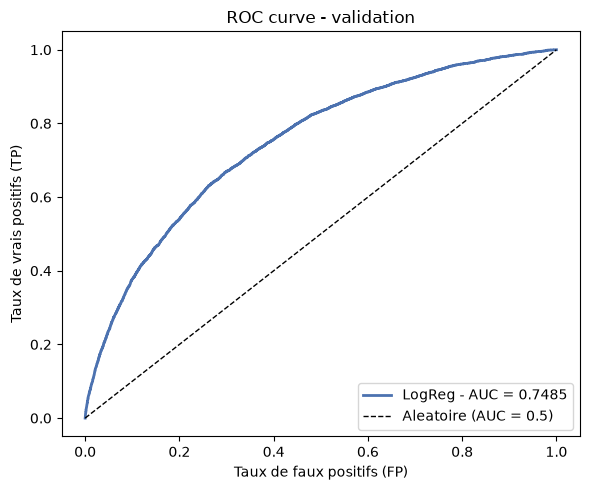

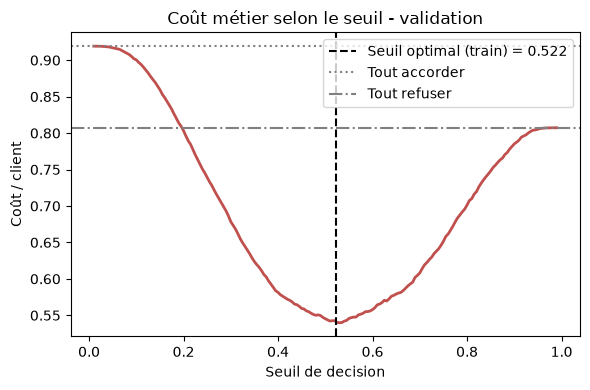

2026/10/24 18:17:48 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'home-credit-logreg' already exists. Creating a new version of this model...


2026/10/24 18:17:51 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: home-credit-logreg, version 5


Created version '5' of model 'home-credit-logreg'.



Run ID       : f94dd894cc554696baea05e2b2898b22
Modèle loggé : models:/m-5a45f3bffc1b47b3b2b12044754aa0e6
🏃 View run baseline_logreg at: http://127.0.0.1:5000/#/experiments/1/runs/f94dd894cc554696baea05e2b2898b22
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [23]:
### 8.3 — baseline LogisticRegression (toutes les features)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from mlflow.models import infer_signature
import mlflow, mlflow.sklearn, time

# pandas 3 : les colonnes string ont le dtype 'str' (plus 'object') -> is_numeric_dtype
cat_idx = [i for i, c in enumerate(X_tr.columns) if not pd.api.types.is_numeric_dtype(X_tr[c])]
num_idx = [i for i, c in enumerate(X_tr.columns) if i not in cat_idx]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_idx),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ]), cat_idx),
])

lr_model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        class_weight="balanced", max_iter=1000, solver="lbfgs", random_state=42,
    )),
])

mlflow.set_experiment("home-credit-scoring")
REGISTRY_NAME = "home-credit-logreg"

t0 = time.perf_counter()
lr_model.fit(X_tr, y_tr)
fit_seconds = time.perf_counter() - t0

y_proba_tr = lr_model.predict_proba(X_tr)[:, 1]
y_proba_va = lr_model.predict_proba(X_va)[:, 1]

with mlflow.start_run(run_name="baseline_logreg") as run:
    mlflow.log_params({
        "model_family": "LogisticRegression",
        "n_features_in": X_tr.shape[1],
        "cat_features": len(cat_idx),
        "num_features": len(num_idx),
        "class_weight": "balanced",
        "solver": "lbfgs",
        "max_iter": 1000,
        "train_rows": len(X_tr),
        "fn_cost": FN_COST,
        "fp_cost": FP_COST,
    })
    mlflow.set_tags({
        "stage": "baseline",
        "dataset": "application_train",
        "validation": "stratified_holdout_20pct",
    })

    print("=== Train ===")
    m_tr = evaluate_and_log(y_tr, y_proba_tr, prefix="train_")
    print("\n=== Validation (seuil optimisé sur le train) ===")
    m_va = evaluate_and_log(y_va, y_proba_va, prefix="val_", threshold=m_tr["train_best_threshold"])
    mlflow.log_metric("fit_seconds", fit_seconds)
    mlflow.log_metric("n_predictive_features", len(lr_model.named_steps["prep"].get_feature_names_out()))

    # --- Courbes (ROC + coût selon le seuil) -> artifacts du run ---
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve

    val_auc = m_va['val_roc_auc']
    val_thr = m_va['val_best_threshold']

    fpr, tpr, _ = roc_curve(y_va, y_proba_va)
    fig_roc, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr, tpr, color='#4C72B0', lw=2,
            label=f'LogReg - AUC = {val_auc:.4f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatoire (AUC = 0.5)')
    ax.set_xlabel('Taux de faux positifs (FP)')
    ax.set_ylabel('Taux de vrais positifs (TP)')
    ax.set_title('ROC curve - validation')
    ax.legend(loc='lower right')
    plt.tight_layout()
    mlflow.log_figure(fig_roc, 'roc_curve_val.png')
    plt.show()

    thr_grid = np.linspace(0.01, 0.99, 197)
    cost_grid = [business_cost(y_va, y_proba_va, t) for t in thr_grid]
    fig_cost, ax = plt.subplots(figsize=(6, 4))
    ax.plot(thr_grid, cost_grid, color='#C0504D', lw=2)
    ax.axvline(val_thr, color='k', ls='--',
               label=f'Seuil optimal (train) = {val_thr:.3f}')
    ax.axhline(FP_COST * (1 - y_va.mean()), color='gray', ls=':', label='Tout accorder')
    ax.axhline(FN_COST * y_va.mean(), color='gray', ls='-.', label='Tout refuser')
    ax.set_xlabel('Seuil de decision')
    ax.set_ylabel('Coût / client')
    ax.set_title('Coût métier selon le seuil - validation')
    ax.legend()
    plt.tight_layout()
    mlflow.log_figure(fig_cost, 'cost_vs_threshold_val.png')
    plt.show()

    # Signature sur les features BRUTES : le pipeline embarque le preprocessing
    signature = infer_signature(X_va, y_proba_va)

    model_info = mlflow.sklearn.log_model(
        lr_model,
        name="model",
        signature=signature,
        input_example=X_va.head(5),
        registered_model_name=REGISTRY_NAME,
        # skops (safe logging MLflow 3) : types de confiance
        skops_trusted_types=["numpy.dtype"],
    )

    print(f"\nRun ID       : {run.info.run_id}")
    print(f"Modèle loggé : {model_info.model_uri}")


[200]	valid_0's binary_logloss: 0.245788


best iteration : 238 / 3,000


=== Train ===


  ROC-AUC : 0.8121 | PR-AUC : 0.3227 | F1 : 0.3135
  Seuil utilisé : 0.0888
  Coût/client @seuil : 0.4571  (vs 0.7857 @0.5)
  Matrice de confusion : TP=14,346 FP=57,313 FN=5,514 TN=168,835

=== Validation (seuil optimisé sur le train) ===
  ROC-AUC : 0.7585 | PR-AUC : 0.2490 | F1 : 0.2800
  Seuil utilisé : 0.0888
  Coût/client @seuil : 0.5269  (vs 0.7926 @0.5)
  Matrice de confusion : TP=3,182 FP=14,578 FN=1,783 TN=41,960


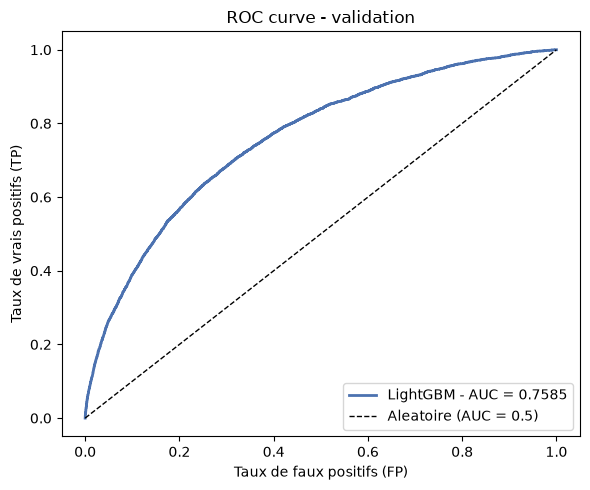

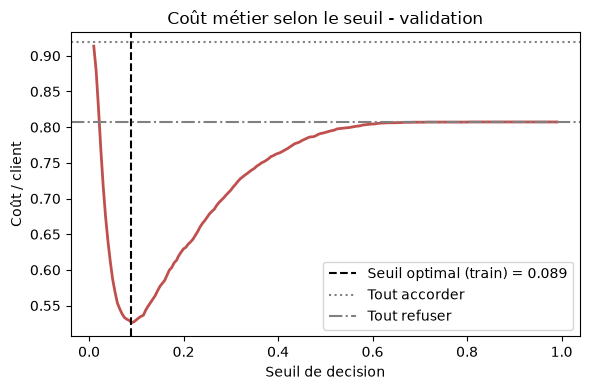

2026/10/24 18:18:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'home-credit-lightgbm' already exists. Creating a new version of this model...


2026/10/24 18:19:00 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: home-credit-lightgbm, version 5


Created version '5' of model 'home-credit-lightgbm'.



Run ID       : 7efa855914ea4c42a89ca809fb473ef7
Modèle loggé : models:/m-44c3a7b4c2b44ec4b94ab720cff731e4
🏃 View run baseline_lightgbm at: http://127.0.0.1:5000/#/experiments/1/runs/7efa855914ea4c42a89ca809fb473ef7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [24]:
### 8.4 — baseline LightGBM (toutes les features)
import time
import lightgbm as lgb
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from mlflow.models import infer_signature

# Encodage ordinal : LightGBM gère nativement les catégories (pas de OHE nécessaire)
cat_cols_lgb = [c for c in X_tr.columns if not pd.api.types.is_numeric_dtype(X_tr[c])]
preprocess_lgb = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols_lgb)],
    remainder='passthrough',
)
X_tr_lgb = preprocess_lgb.fit_transform(X_tr)
X_va_lgb = preprocess_lgb.transform(X_va)
cat_idx_lgb = list(range(len(cat_cols_lgb)))  # colonnes catégorielles en premier

lgb_model = lgb.LGBMClassifier(
    objective='binary',
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

t0 = time.perf_counter()
lgb_model.fit(
    X_tr_lgb, y_tr,
    eval_X=X_va_lgb, eval_y=y_va,
    categorical_feature=cat_idx_lgb,
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(200)],
)
fit_seconds = time.perf_counter() - t0
print(f"best iteration : {lgb_model.best_iteration_:,} / {lgb_model.n_estimators:,}")

y_proba_tr = lgb_model.predict_proba(X_tr_lgb)[:, 1]
y_proba_va = lgb_model.predict_proba(X_va_lgb)[:, 1]

mlflow.set_experiment('home-credit-scoring')
REGISTRY_NAME_LGB = 'home-credit-lightgbm'

with mlflow.start_run(run_name='baseline_lightgbm') as run:
    mlflow.log_params({
        'model_family': 'LightGBM',
        'n_features_in': X_tr.shape[1],
        'cat_features': len(cat_cols_lgb),
        'num_features': X_tr.shape[1] - len(cat_cols_lgb),
        'n_estimators': lgb_model.n_estimators,
        'learning_rate': 0.05,
        'num_leaves': 31,
        'early_stopping_rounds': 50,
        'train_rows': len(X_tr),
        'fn_cost': FN_COST,
        'fp_cost': FP_COST,
    })
    mlflow.set_tags({
        'stage': 'baseline',
        'dataset': 'application_train',
        'validation': 'stratified_holdout_20pct',
        'custom_metric': 'business_cost_fn10_fp1',
    })

    print('=== Train ===')
    m_tr = evaluate_and_log(y_tr, y_proba_tr, prefix='train_')
    print('\n=== Validation (seuil optimisé sur le train) ===')
    m_va = evaluate_and_log(y_va, y_proba_va, prefix='val_', threshold=m_tr['train_best_threshold'])

    mlflow.log_metric('fit_seconds', fit_seconds)
    mlflow.log_metric('best_iteration', int(lgb_model.best_iteration_))

    # --- Courbes (ROC + coût selon le seuil) -> artifacts du run ---
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve

    val_auc = m_va['val_roc_auc']
    val_thr = m_va['val_best_threshold']

    fpr, tpr, _ = roc_curve(y_va, y_proba_va)
    fig_roc, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr, tpr, color='#4C72B0', lw=2,
            label=f'LightGBM - AUC = {val_auc:.4f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatoire (AUC = 0.5)')
    ax.set_xlabel('Taux de faux positifs (FP)')
    ax.set_ylabel('Taux de vrais positifs (TP)')
    ax.set_title('ROC curve - validation')
    ax.legend(loc='lower right')
    plt.tight_layout()
    mlflow.log_figure(fig_roc, 'roc_curve_val.png')
    plt.show()

    thr_grid = np.linspace(0.01, 0.99, 197)
    cost_grid = [business_cost(y_va, y_proba_va, t) for t in thr_grid]
    fig_cost, ax = plt.subplots(figsize=(6, 4))
    ax.plot(thr_grid, cost_grid, color='#C0504D', lw=2)
    ax.axvline(val_thr, color='k', ls='--',
               label=f'Seuil optimal (train) = {val_thr:.3f}')
    ax.axhline(FP_COST * (1 - y_va.mean()), color='gray', ls=':', label='Tout accorder')
    ax.axhline(FN_COST * y_va.mean(), color='gray', ls='-.', label='Tout refuser')
    ax.set_xlabel('Seuil de decision')
    ax.set_ylabel('Coût / client')
    ax.set_title('Coût métier selon le seuil - validation')
    ax.legend()
    plt.tight_layout()
    mlflow.log_figure(fig_cost, 'cost_vs_threshold_val.png')
    plt.show()

    # Signature sur les features BRUTES : le pipeline embarque l'encodage
    signature = infer_signature(X_va, y_proba_va)

    model_info = mlflow.sklearn.log_model(
        Pipeline([('encode', preprocess_lgb), ('clf', lgb_model)]),
        name='model',
        signature=signature,
        input_example=X_va.head(5),
        registered_model_name=REGISTRY_NAME_LGB,
        # skops (safe logging MLflow 3) : types de confiance
        skops_trusted_types=[
            "collections.OrderedDict",
            "lightgbm.basic.Booster",
            "lightgbm.sklearn.LGBMClassifier",
        ],
    )

    print(f'\nRun ID       : {run.info.run_id}')
    print(f'Modèle loggé : {model_info.model_uri}')

### 8.5 — lecture des résultats

Le critère de choix est le **`val_cost_per_client_best`** (coût/client en validation, seuil optimisé sur le train). Il doit être **inférieur au coût « tout refuser »** (≈ 0,80) pour que le modèle apporte de la valeur. Le seuil optimal sera bien plus bas que 0,5 (≈ 0,09 en théorie pour un FN 10× FP) : le modèle "préfère" prendre des FP pour éviter les FN coûteux.

Les deux modèles sont enregistrés dans le **Model Registry MLflow** (`home-credit-logreg`, `home-credit-lightgbm`) avec signature et exemple d'entrée → prêts à servir. Prochaine étape naturelle : tuning d'hyperparamètres (optuna / recherche grid) guidé par le coût métier, puis évaluation finale sur `application_test`.

## 9 : cross-validation & comparaison ---
La validation holdout (20 %) ne suffit pas à juger de la stabilité : on complète par une **CV 5-fold stratifiée** sur le train. **Règle** : pour chaque fold, le seuil optimal est optimisé sur le fold d'entraînement puis appliqué au fold de validation (pas de fuite). Le modèle artefact (8.3/8.4) reste entraîné sur le train complet — la CV valide la stabilité, elle ne produit pas l'artefact.

In [25]:
### 9.1 — CV 5-fold : LogisticRegression
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_tr, y_tr), start=1):
    X_f_tr, X_f_va = X_tr.iloc[tr_idx], X_tr.iloc[va_idx]
    y_f_tr, y_f_va = y_tr.iloc[tr_idx], y_tr.iloc[va_idx]

    # même preprocessing que 8.3, fit sur le fold d'entraînement uniquement
    cat_idx = [i for i, c in enumerate(X_f_tr.columns)
               if not pd.api.types.is_numeric_dtype(X_f_tr[c])]
    num_idx = [i for i, c in enumerate(X_f_tr.columns) if i not in cat_idx]
    fold_preprocess = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), num_idx),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
        ]), cat_idx),
    ])
    fold_model = Pipeline([
        ('prep', fold_preprocess),
        ('clf', LogisticRegression(
            class_weight='balanced', max_iter=1000, solver='lbfgs', random_state=42,
        )),
    ])
    fold_model.fit(X_f_tr, y_f_tr)

    proba_tr = fold_model.predict_proba(X_f_tr)[:, 1]
    proba_va = fold_model.predict_proba(X_f_va)[:, 1]
    thr, _ = optimal_threshold(y_f_tr, proba_tr)  # seuil optimisé sur le fold train
    rows.append({
        'fold': fold,
        'roc_auc': roc_auc_score(y_f_va, proba_va),
        'pr_auc': average_precision_score(y_f_va, proba_va),
        'seuil': thr,
        'cout': business_cost(y_f_va, proba_va, thr),
    })
    print(f"fold {fold} — ROC-AUC : {rows[-1]['roc_auc']:.4f} | "
          f"coût/client : {rows[-1]['cout']:.4f} (seuil {thr:.3f})")

cv_logreg = pd.DataFrame(rows)
print('\n=== CV LogReg (5 folds) ===')
print(f"ROC-AUC     : {cv_logreg['roc_auc'].mean():.4f} ± {cv_logreg['roc_auc'].std():.4f}")
print(f"PR-AUC      : {cv_logreg['pr_auc'].mean():.4f} ± {cv_logreg['pr_auc'].std():.4f}")
print(f"Coût/client : {cv_logreg['cout'].mean():.4f} ± {cv_logreg['cout'].std():.4f}")

with mlflow.start_run(run_name='cv_logreg'):
    mlflow.log_params({'cv_folds': 5, 'model_family': 'LogisticRegression',
                       'fn_cost': FN_COST, 'fp_cost': FP_COST})
    mlflow.set_tags({'stage': 'cv', 'model_family': 'LogisticRegression'})
    mlflow.log_metrics({
        'cv_roc_auc_mean': cv_logreg['roc_auc'].mean(),
        'cv_roc_auc_std': cv_logreg['roc_auc'].std(),
        'cv_pr_auc_mean': cv_logreg['pr_auc'].mean(),
        'cv_pr_auc_std': cv_logreg['pr_auc'].std(),
        'cv_cost_mean': cv_logreg['cout'].mean(),
        'cv_cost_std': cv_logreg['cout'].std(),
    })
    print('Run cv_logreg créé dans MLflow')

fold 1 — ROC-AUC : 0.7453 | coût/client : 0.5456 (seuil 0.513)


fold 2 — ROC-AUC : 0.7435 | coût/client : 0.5448 (seuil 0.519)


fold 3 — ROC-AUC : 0.7508 | coût/client : 0.5351 (seuil 0.515)


fold 4 — ROC-AUC : 0.7434 | coût/client : 0.5507 (seuil 0.510)


fold 5 — ROC-AUC : 0.7442 | coût/client : 0.5548 (seuil 0.505)

=== CV LogReg (5 folds) ===
ROC-AUC     : 0.7454 ± 0.0031
PR-AUC      : 0.2188 ± 0.0059
Coût/client : 0.5462 ± 0.0074


Run cv_logreg créé dans MLflow
🏃 View run cv_logreg at: http://127.0.0.1:5000/#/experiments/1/runs/dd3cec3db5a34273976c167f77355b5d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


fold 1 — ROC-AUC : 0.7545 | coût/client : 0.5387 | best_iter : 329


fold 2 — ROC-AUC : 0.7545 | coût/client : 0.5292 | best_iter : 192


fold 3 — ROC-AUC : 0.7567 | coût/client : 0.5272 | best_iter : 234


fold 4 — ROC-AUC : 0.7583 | coût/client : 0.5294 | best_iter : 299


fold 5 — ROC-AUC : 0.7537 | coût/client : 0.5454 | best_iter : 364

=== CV LightGBM (5 folds) ===
ROC-AUC     : 0.7555 ± 0.0019
PR-AUC      : 0.2384 ± 0.0062
Coût/client : 0.5340 ± 0.0078


Run cv_lightgbm créé dans MLflow
🏃 View run cv_lightgbm at: http://127.0.0.1:5000/#/experiments/1/runs/ce0c8d388b3a4548b8f0cf4335c6b3e0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


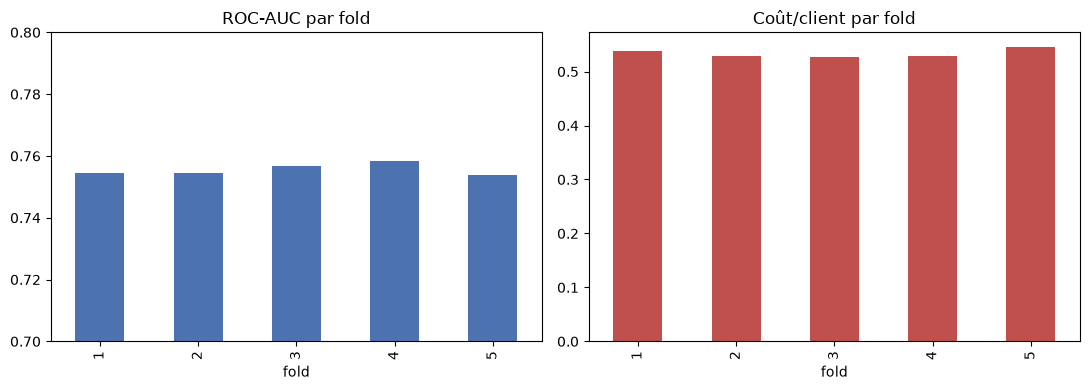

In [26]:
### 9.2 — CV 5-fold : LightGBM
rows = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_tr, y_tr), start=1):
    # encodage ordinal fit sur le fold d'entraînement uniquement
    prep_fold = ColumnTransformer(
        [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols_lgb)],
        remainder='passthrough',
    )
    X_f_tr = prep_fold.fit_transform(X_tr.iloc[tr_idx])
    X_f_va = prep_fold.transform(X_tr.iloc[va_idx])
    y_f_tr, y_f_va = y_tr.iloc[tr_idx], y_tr.iloc[va_idx]

    fold_model = lgb.LGBMClassifier(
        objective='binary', n_estimators=3000, learning_rate=0.05,
        num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=-1,
    )
    fold_model.fit(
        X_f_tr, y_f_tr,
        eval_X=X_f_va, eval_y=y_f_va,
        categorical_feature=list(range(len(cat_cols_lgb))),
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )

    proba_tr = fold_model.predict_proba(X_f_tr)[:, 1]
    proba_va = fold_model.predict_proba(X_f_va)[:, 1]
    thr, _ = optimal_threshold(y_f_tr, proba_tr)
    rows.append({
        'fold': fold,
        'roc_auc': roc_auc_score(y_f_va, proba_va),
        'pr_auc': average_precision_score(y_f_va, proba_va),
        'seuil': thr,
        'cout': business_cost(y_f_va, proba_va, thr),
        'best_iter': int(fold_model.best_iteration_),
    })
    print(f"fold {fold} — ROC-AUC : {rows[-1]['roc_auc']:.4f} | "
          f"coût/client : {rows[-1]['cout']:.4f} | best_iter : {rows[-1]['best_iter']}")

cv_lightgbm = pd.DataFrame(rows)
print('\n=== CV LightGBM (5 folds) ===')
print(f"ROC-AUC     : {cv_lightgbm['roc_auc'].mean():.4f} ± {cv_lightgbm['roc_auc'].std():.4f}")
print(f"PR-AUC      : {cv_lightgbm['pr_auc'].mean():.4f} ± {cv_lightgbm['pr_auc'].std():.4f}")
print(f"Coût/client : {cv_lightgbm['cout'].mean():.4f} ± {cv_lightgbm['cout'].std():.4f}")

# Figure : performance par fold
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cv_lightgbm.plot.bar(x='fold', y='roc_auc', ax=axes[0], legend=False, color='#4C72B0')
axes[0].set_title('ROC-AUC par fold')
axes[0].set_ylim(0.70, 0.80)
cv_lightgbm.plot.bar(x='fold', y='cout', ax=axes[1], legend=False, color='#C0504D')
axes[1].set_title('Coût/client par fold')
plt.tight_layout()

with mlflow.start_run(run_name='cv_lightgbm'):
    mlflow.log_params({'cv_folds': 5, 'model_family': 'LightGBM',
                       'fn_cost': FN_COST, 'fp_cost': FP_COST})
    mlflow.set_tags({'stage': 'cv', 'model_family': 'LightGBM'})
    mlflow.log_metrics({
        'cv_roc_auc_mean': cv_lightgbm['roc_auc'].mean(),
        'cv_roc_auc_std': cv_lightgbm['roc_auc'].std(),
        'cv_pr_auc_mean': cv_lightgbm['pr_auc'].mean(),
        'cv_pr_auc_std': cv_lightgbm['pr_auc'].std(),
        'cv_cost_mean': cv_lightgbm['cout'].mean(),
        'cv_cost_std': cv_lightgbm['cout'].std(),
    })
    mlflow.log_figure(fig, 'cv_folds_performance.png')
    print('Run cv_lightgbm créé dans MLflow')
plt.show()

Run comparaison_baselines créé dans MLflow
🏃 View run comparaison_baselines at: http://127.0.0.1:5000/#/experiments/1/runs/8527d2aef2fa4158ae2971c028d159cd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


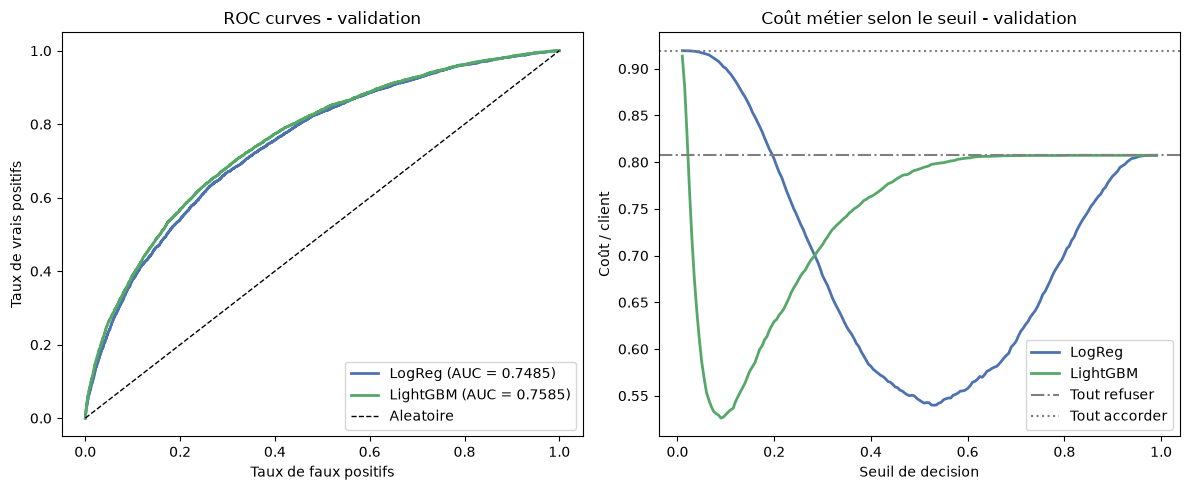

In [27]:
### 9.3 — comparaison des deux baselines (validation)
# Les probas de validation ont été écrasées par LightGBM en 8.4 : on re-prédit avec LogReg.
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

y_proba_va_lr = lr_model.predict_proba(X_va)[:, 1]
y_proba_va_lgb = y_proba_va  # celles de 8.4

# seuil optimal de chaque modèle, optimisé sur le train
thr_lr, _ = optimal_threshold(y_tr, lr_model.predict_proba(X_tr)[:, 1])
thr_lgb, _ = optimal_threshold(y_tr, lgb_model.predict_proba(X_tr_lgb)[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
for name, proba, color in [
    ('LogReg', y_proba_va_lr, '#4C72B0'),
    ('LightGBM', y_proba_va_lgb, '#55A868'),
]:
    fpr, tpr, _ = roc_curve(y_va, proba)
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f'{name} (AUC = {roc_auc_score(y_va, proba):.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatoire')
ax.set_xlabel('Taux de faux positifs')
ax.set_ylabel('Taux de vrais positifs')
ax.set_title('ROC curves - validation')
ax.legend(loc='lower right')

ax = axes[1]
thr_grid = np.linspace(0.01, 0.99, 197)
for name, proba, color in [
    ('LogReg', y_proba_va_lr, '#4C72B0'),
    ('LightGBM', y_proba_va_lgb, '#55A868'),
]:
    costs = [business_cost(y_va, proba, t) for t in thr_grid]
    ax.plot(thr_grid, costs, color=color, lw=2, label=name)
ax.axhline(FN_COST * y_va.mean(), color='gray', ls='-.', label='Tout refuser')
ax.axhline(FP_COST * (1 - y_va.mean()), color='gray', ls=':', label='Tout accorder')
ax.set_xlabel('Seuil de decision')
ax.set_ylabel('Coût / client')
ax.set_title('Coût métier selon le seuil - validation')
ax.legend()
plt.tight_layout()

with mlflow.start_run(run_name='comparaison_baselines'):
    mlflow.log_figure(fig, 'comparaison_baselines_val.png')
    mlflow.log_metrics({
        'val_roc_auc_logreg': roc_auc_score(y_va, y_proba_va_lr),
        'val_roc_auc_lightgbm': roc_auc_score(y_va, y_proba_va_lgb),
        'val_cost_logreg': business_cost(y_va, y_proba_va_lr, thr_lr),
        'val_cost_lightgbm': business_cost(y_va, y_proba_va_lgb, thr_lgb),
    })
    print('Run comparaison_baselines créé dans MLflow')
plt.show()

### 9.4 — bilan CV vs holdout

- **CV 5-fold** : moyenne ± écart-type du ROC-AUC et du coût/client — la stabilité compte autant que la moyenne pour choisir un modèle en production.
- **Artefacts** : chaque run d'entraînement (8.3/8.4) contient `roc_curve_val.png` et `cost_vs_threshold_val.png` ; les runs de CV contiennent `cv_folds_performance.png`.
- Le modèle enregistré au Registry reste celui entraîné sur le **train complet** (8.3/8.4) — la CV sert à valider la stabilité.

➡️ Prochaine étape : section 10 — feature engineering automatisé (OpenFE), puis tuning guidé par le coût métier en CV.

## 10 : feature engineering automatisé (OpenFE) ---
**OpenFE** (ICML 2023, référence SOTA de l'AutoFE hors LLM) : génération de features candidates (opérateurs unaires, combinaisons 2-à-2 `+ - × ÷`, opérateurs `GroupByThen*`), puis **sélection en 2 stages** (pruning prédictif puis sélection itérative par importance LightGBM).

**Stratégie CPU** (16 cœurs, contrainte de charge) :
- recherche sur un **sous-échantillon stratifié de 5 000 lignes** (pas les 246 000) ;
- espace de candidats restreint aux **top-30 features de base par importance LightGBM** + toutes les catégorielles (≈ 3 000 candidats au lieu de 71 729 — mécanisme `candidate_features_list` prévu par OpenFE) ;
- `n_jobs=8` (moitié des cœurs) ;
- `transform` ensuite appliqué au train/validation complets (coût négligeable : calcul arithmétique).

Les fichiers `data/processed/*_prepared.csv` restent intouchés : on travaille sur des **copies** et on sauvegarde le résultat augmenté dans `train_fe.csv` / `val_fe.csv`.

In [28]:
### 10.1 — copie du dataset & échantillon de recherche
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from openfe import OpenFE, get_candidate_features
import lightgbm as lgb

# Copie de travail : les snapshots *_prepared.csv restent intouchés
X_tr_fe = X_tr.copy()
X_va_fe = X_va.copy()

# Sous-échantillon stratifié pour la recherche (contrainte CPU)
_, X_search, _, y_search = train_test_split(
    X_tr, y_tr, train_size=5000, stratify=y_tr, random_state=42,
)

# Espace de candidats restreint : top-30 features de base (importance LightGBM rapide)
enc_imp = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)],
    remainder='passthrough',
)
X_search_enc = enc_imp.fit_transform(X_search)
imp_names = [n.split('__', 1)[-1] for n in enc_imp.get_feature_names_out()]
gbm_imp = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=15,
    random_state=42, n_jobs=8, verbosity=-1,
)
gbm_imp.fit(X_search_enc, y_search)
imp = pd.Series(gbm_imp.feature_importances_, index=imp_names).sort_values(ascending=False)
top_num = [n for n in imp.index[:30] if n not in cat_cols]

candidates = get_candidate_features(
    numerical_features=top_num,
    categorical_features=cat_cols,
    order=1,
)
print(f'top 10 features de base par importance : {list(imp.index[:10])}')
print(f"espace de candidats : {len(candidates)} (vs 71 729 sans restriction)")

top 10 features de base par importance : ['EXT_SOURCE_3', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'AMT_CREDIT', 'DAYS_BIRTH', 'AMT_ANNUITY', 'DAYS_EMPLOYED', 'AMT_GOODS_PRICE', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']
espace de candidats : 4406 (vs 71 729 sans restriction)


In [29]:
### 10.2 — recherche OpenFE (stage I + stage II)
from openfe.utils import tree_to_formula

ofe = OpenFE()
t0 = time.perf_counter()
new_features = ofe.fit(
    data=X_search,
    label=pd.DataFrame(y_search),
    task='classification',
    metric='auc',
    candidate_features_list=candidates,
    stage1_metric='predictive',
    min_candidate_features=200,
    n_jobs=8,          # moitié des cœurs
    seed=42,
    verbose=True,
    tmp_save_path='/tmp/opencode/openfe_tmp.feather',
)
openfe_search_seconds = time.perf_counter() - t0
print(f'\nRecherche terminée en {openfe_search_seconds:.0f} s — {len(new_features)} features découvertes')

print('\nTop 15 des features découvertes (formule, score) :')
for node, score in ofe.new_features_scores_list[:15]:
    print(f'  {tree_to_formula(node):60s} {score:,.1f}')

The number of candidate features is 4406
Start stage I selection.


  0%|          | 0/32 [00:00<?, ?it/s]

./.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


./.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


./.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

100%|██████████| 29/29 [00:22<00:00,  1.61it/s]

100%|██████████| 29/29 [00:22<00:00,  1.26it/s]

Finish data processing.


./.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



Recherche terminée en 236 s — 290 features découvertes

Top 15 des features découvertes (formule, score) :
  (EXT_SOURCE_3+EXT_SOURCE_2)                                  35,037.8
  (AMT_CREDIT/AMT_ANNUITY)                                     5,539.6
  (EXT_SOURCE_3*EXT_SOURCE_2)                                  2,641.9
  (EXT_SOURCE_3+EXT_SOURCE_1)                                  2,629.2
  (AMT_ANNUITY/AMT_GOODS_PRICE)                                1,926.0
  max(EXT_SOURCE_3,EXT_SOURCE_1)                               1,612.7
  (EXT_SOURCE_1/OWN_CAR_AGE)                                   1,322.4
  (EXT_SOURCE_1*DAYS_EMPLOYED)                                 1,092.0
  (EXT_SOURCE_1+EXT_SOURCE_2)                                  1,040.4
  (EXT_SOURCE_1*DAYS_BIRTH)                                    989.6
  (AMT_GOODS_PRICE/FLAG_DOCUMENT_3)                            858.2
  GroupByThenRank(AMT_GOODS_PRICE,NAME_CONTRACT_TYPE)          811.4
  (DAYS_BIRTH+DAYS_EMPLOYED)                 

In [30]:
### 10.3 — application au train / validation complets
X_tr_fe, X_va_fe = ofe.transform(X_tr_fe, X_va_fe, new_features, n_jobs=8)

# sécurité : inf -> NaN (LightGBM gère NaN), catégories autoFE -> codes
X_tr_fe = X_tr_fe.replace([np.inf, -np.inf], np.nan)
X_va_fe = X_va_fe.replace([np.inf, -np.inf], np.nan)
for c in X_tr_fe.columns:
    if str(X_tr_fe[c].dtype) == 'category':
        X_tr_fe[c] = X_tr_fe[c].cat.codes
        X_va_fe[c] = X_va_fe[c].cat.codes

print('shape après FE — train :', X_tr_fe.shape, '| validation :', X_va_fe.shape)
print('nouvelles colonnes :', X_tr_fe.shape[1] - X_tr.shape[1])

# Snapshots du dataset augmenté (copie du train augmenté)
pd.concat([X_tr_fe, y_tr], axis=1).to_csv(PROCESSED_DIR / 'train_fe.csv', index=False)
pd.concat([X_va_fe, y_va], axis=1).to_csv(PROCESSED_DIR / 'val_fe.csv', index=False)
print('sauvegardé : data/processed/train_fe.csv, data/processed/val_fe.csv')

Start transforming data.


Time spent calculating new features 0:02:34.911127.


Finish transformation.


shape après FE — train : (246008, 400) | validation : (61503, 400)
nouvelles colonnes : 290


sauvegardé : data/processed/train_fe.csv, data/processed/val_fe.csv


In [31]:
### 10.4 — validation du gain : LightGBM sur features augmentées
cat_cols_fe = [c for c in X_tr_fe.columns if not pd.api.types.is_numeric_dtype(X_tr_fe[c])]

preprocess_fe = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols_fe)],
    remainder='passthrough',
)
X_tr_fe_enc = preprocess_fe.fit_transform(X_tr_fe)
X_va_fe_enc = preprocess_fe.transform(X_va_fe)

lgb_fe = lgb.LGBMClassifier(
    objective='binary', n_estimators=3000, learning_rate=0.05,
    num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=-1,
)

t0 = time.perf_counter()
lgb_fe.fit(
    X_tr_fe_enc, y_tr,
    eval_X=X_va_fe_enc, eval_y=y_va,
    categorical_feature=list(range(len(cat_cols_fe))),
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
fit_seconds = time.perf_counter() - t0
print(f"best iteration : {lgb_fe.best_iteration_:,} / {lgb_fe.n_estimators:,}")

y_proba_tr_fe = lgb_fe.predict_proba(X_tr_fe_enc)[:, 1]
y_proba_va_fe = lgb_fe.predict_proba(X_va_fe_enc)[:, 1]
thr_fe, _ = optimal_threshold(y_tr, y_proba_tr_fe)

print(f"\n=== Validation — LightGBM + OpenFE ({X_tr_fe.shape[1]} features) ===")
print(f'ROC-AUC      : {roc_auc_score(y_va, y_proba_va_fe):.4f}')
print(f'PR-AUC       : {average_precision_score(y_va, y_proba_va_fe):.4f}')
print(f'Seuil optimal : {thr_fe:.4f}')
print(f"Coût/client  : {business_cost(y_va, y_proba_va_fe, thr_fe):.4f}")
# référence = la baseline LightGBM de 8.4 (y_proba_va n'a pas été écrasée)
print(f"référence sans FE : coût {business_cost(y_va, y_proba_va, m_tr['train_best_threshold']):.4f} "
      f"@seuil {m_tr['train_best_threshold']:.4f}")

with mlflow.start_run(run_name='lightgbm_autofe'):
    mlflow.log_params({
        'model_family': 'LightGBM',
        'feature_engineering': 'OpenFE',
        'n_features': X_tr_fe.shape[1],
        'n_autofeatures': len(new_features),
        'search_rows': len(X_search),
        'search_n_jobs': 8,
        'n_estimators': lgb_fe.n_estimators,
        'learning_rate': 0.05,
        'num_leaves': 31,
        'train_rows': len(X_tr),
        'fn_cost': FN_COST,
        'fp_cost': FP_COST,
    })
    mlflow.set_tags({'stage': 'autofe', 'custom_metric': 'business_cost_fn10_fp1'})
    mlflow.log_metrics({
        'val_roc_auc': roc_auc_score(y_va, y_proba_va_fe),
        'val_pr_auc': average_precision_score(y_va, y_proba_va_fe),
        'val_best_threshold': thr_fe,
        'val_cost_per_client_best': business_cost(y_va, y_proba_va_fe, thr_fe),
        'best_iteration': int(lgb_fe.best_iteration_),
        'fit_seconds': fit_seconds,
        'openfe_search_seconds': openfe_search_seconds,
    })
    print('Run lightgbm_autofe créé dans MLflow')

best iteration : 252 / 3,000



=== Validation — LightGBM + OpenFE (400 features) ===
ROC-AUC      : 0.7656
PR-AUC       : 0.2597
Seuil optimal : 0.0899
Coût/client  : 0.5187
référence sans FE : coût 0.5269 @seuil 0.0888


Run lightgbm_autofe créé dans MLflow
🏃 View run lightgbm_autofe at: http://127.0.0.1:5000/#/experiments/1/runs/3c49dc83312041cfad0c34ba4f1b23ca
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### 10.5 — bilan du feature engineering

- OpenFE découvre des features cohérentes avec le métier : ratios de crédit (`AMT_CREDIT/AMT_ANNUITY`, `AMT_ANNUITY/AMT_GOODS_PRICE`), combinaisons de scores externes (`EXT_SOURCE_3+EXT_SOURCE_2`), interactions temporelles (`EXT_SOURCE_1*DAYS_EMPLOYED`) et même des agrégats par groupe (`GroupByThenRank`).
- Le gain se lit en **coût/client en validation** (cellule 10.4) : c'est le critère pour décider si les features autoFE sont conservées pour le tuning.
- Le gain est positif (−0,0082 de coût/client) : les 400 features passent à la **section 11 — feature selection** (filtre variance + BorutaShap) avant le tuning.

## 11 : feature selection — filtre variance + BorutaShap ---
Sur les 400 features (110 base + 290 OpenFE), certaines sont **sans variance** (constantes ou
quasi-constantes issues des opérateurs) et d'autres ont un **impact nul** (pas meilleures que du bruit).

**BorutaShap** (protocole Boruta + importance par valeurs SHAP) — sélection *all-relevant* :
1. chaque feature réelle est comparée à ses **shadow features** (copies mélangées) —
   `percentile=50` : 200 shadows pour 400 réelles, pour abaisser la barre du max-shadow
   (protocole strict `percentile=100` sur-prune massivement : cf. bilan 11.5) ;
2. LightGBM (200 arbres) entraîné sur réels+shadows, importance = **|SHAP| moyen** (z-score) ;
3. *hit* si importance > meilleur shadow ; **test binomial exact** (`p=0.05`) + **correction FDR** ;
4. après `n_trials=25` : `confirmed` / `rejected` / `tentative` (tranché par `TentativeRoughFix`).

**Bornage CPU** : 30 000 lignes stratifiées (vs 246 008), `n_jobs=8` (½ des 16 threads), ~20 s/trial → ≈ 8-13 min.
Encodage ordinal des catégorielles avant Boruta (SHAP exige du numérique), noms de colonnes conservés.

In [32]:
### 11.1 — compat BorutaShap & filtre variance
import numpy as _np, scipy.stats as _st

# BorutaShap 1.0.17 est antérieur à scipy>=1.12 (binom_test supprimé) et numpy>=2.0 (np.NaN supprimé)
if not hasattr(_st, 'binom_test'):
    def _binom_test(x, n=None, p=0.5, alternative='two-sided'):
        if n is None:
            k, n = int(x[0]), int(x[0] + x[1])
        else:
            k = int(x)
        return _st.binomtest(int(k), int(n), p=p, alternative=alternative).pvalue
    _st.binom_test = _binom_test
if not hasattr(_np, 'NaN'):
    _np.NaN = _np.nan

from BorutaShap import BorutaShap

MAX_QUASI_CONSTANT = 0.999

t0 = time.perf_counter()
is_const = X_tr_fe.nunique(dropna=False) <= 1
frac_top = X_tr_fe.apply(
    lambda s: (s.value_counts(dropna=False).iloc[0] / len(s)) if s.nunique(dropna=False) else 1.0
)
is_quasi = (frac_top > MAX_QUASI_CONSTANT) & ~is_const
to_drop = list(X_tr_fe.columns[is_const | is_quasi])
print(f'constantes : {int(is_const.sum())} | quasi-constantes (>99.9%) : {int(is_quasi.sum())} '
      f'=> {len(to_drop)} supprimées en filtre préalable')
print(f'reste {X_tr_fe.shape[1] - len(to_drop)} features pour BorutaShap ({time.perf_counter()-t0:.0f}s)')

constantes : 0 | quasi-constantes (>99.9%) : 0 => 0 supprimées en filtre préalable
reste 400 features pour BorutaShap (8s)


In [33]:
### 11.2 — BorutaShap : 25 trials sur 30k lignes
SEARCH_ROWS, N_TRIALS = 30000, 25

# encodage ordinal (SHAP exige du numérique) — noms de colonnes conservés
enc_boruta = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)],
    remainder='passthrough',
)
X_tr_enc = pd.DataFrame(
    enc_boruta.fit_transform(X_tr_fe), columns=X_tr_fe.columns, index=X_tr_fe.index,
)

X_search, _, y_search, _ = train_test_split(
    X_tr_enc.drop(columns=to_drop), y_tr,
    train_size=SEARCH_ROWS, stratify=y_tr, random_state=42,
)

boruta_model = lgb.LGBMClassifier(
    n_estimators=200, learning_rate=0.05, num_leaves=31,
    random_state=42, n_jobs=8, verbosity=-1,   # 8 = moitié des cœurs
)
selector = BorutaShap(
    model=boruta_model, importance_measure='shap', classification=True,
    percentile=50, pvalue=0.05,   # 200 shadows (50%) — barre du max-shadow 2x plus basse
)
t0 = time.perf_counter()
selector.fit(X=X_search, y=y_search, n_trials=N_TRIALS, random_state=42, verbose=True)
boruta_seconds = time.perf_counter() - t0
print(f'BorutaShap : {boruta_seconds:.0f}s ({boruta_seconds/N_TRIALS:.0f}s/trial)')

Warning there are missing values in your data !


  0%|          | 0/25 [00:00<?, ?it/s]

  4%|▍         | 1/25 [00:17<06:59, 17.49s/it]

  8%|▊         | 2/25 [00:32<06:13, 16.24s/it]

 12%|█▏        | 3/25 [00:49<05:56, 16.21s/it]

...

 92%|█████████▏| 23/25 [05:35<00:23, 11.84s/it]

 96%|█████████▌| 24/25 [05:46<00:11, 11.51s/it]

100%|██████████| 25/25 [05:57<00:00, 11.27s/it]

100%|██████████| 25/25 [05:57<00:00, 14.30s/it]

61 attributes confirmed important: ['CODE_GENDER', 'NAME_TYPE_SUITE', 'autoFE_f_33', 'autoFE_f_17', 'autoFE_f_62', 'autoFE_f_98', 'OBS_60_CNT_SOCIAL_CIRCLE', 'autoFE_f_37', 'autoFE_f_12', 'autoFE_f_61', 'autoFE_f_22', 'OWN_CAR_AGE', 'autoFE_f_105', 'autoFE_f_35', 'autoFE_f_36', 'autoFE_f_55', 'autoFE_f_70', 'autoFE_f_93', 'HOUR_APPR_PROCESS_START', 'autoFE_f_6', 'autoFE_f_32', 'AMT_CREDIT', 'autoFE_f_5', 'autoFE_f_9', 'autoFE_f_138', 'FLAG_OWN_CAR', 'autoFE_f_30', 'autoFE_f_71', 'autoFE_f_53', 'autoFE_f_4', 'OCCUPATION_TYPE', 'autoFE_f_0', 'autoFE_f_80', 'autoFE_f_8', 'autoFE_f_18', 'autoFE_f_27', 'autoFE_f_133', 'autoFE_f_19', 'autoFE_f_15', 'autoFE_f_2', 'autoFE_f_81', 'autoFE_f_25', 'autoFE_f_91', 'autoFE_f_119', 'autoFE_f_74', 'autoFE_f_83', 'autoFE_f_60', 'autoFE_f_3', 'autoFE_f_20', 'autoFE_f_131', 'autoFE_f_136', 'autoFE_f_1', 'autoFE_f_108', 'FLAG_CONT_MOBILE', 'autoFE_f_29', 'BASEMENTAREA_AVG', 'autoFE_f_126', 'autoFE_f_16', 'autoFE_f_50', 'autoFE_f_49', 'autoFE_f_47']
266 att

In [34]:
### 11.3 — tranchage des tentatives & artefacts de sélection
selector.TentativeRoughFix()

tentative_kept = set(np.atleast_1d(selector.tentative)) - set(selector.rejected) - set(selector.accepted)
confirmed = [c for c in selector.accepted if c not in to_drop]
print(f'confirmed (impact prouvé) : {len(confirmed)}')
print(f'tentative_kept (zone grise, conservées) : {len(tentative_kept)}')
print(f'rejected (impact nul) : {len(selector.rejected)}')
print(f'supprimées filtre variance : {len(to_drop)}')

sel_df = pd.DataFrame({
    'feature': list(X_tr_fe.columns),
    'decision': [
        'confirmed' if c in confirmed else
        'removed_variance' if c in to_drop else
        'tentative_kept' if c in tentative_kept else 'rejected'
        for c in X_tr_fe.columns
    ],
})
sel_df.to_csv(PROCESSED_DIR / 'feature_selection_boruta.csv', index=False)
print('sauvegardé : data/processed/feature_selection_boruta.csv')
print('top 10 confirmées (ordre Boruta) :', confirmed[:10])

0 tentative features are now accepted: []
73 tentative features are now rejected: ['autoFE_f_236' 'autoFE_f_24' 'autoFE_f_185' 'autoFE_f_111' 'autoFE_f_110'
 'autoFE_f_229' 'autoFE_f_21' 'autoFE_f_94' 'autoFE_f_104' 'autoFE_f_137'
 'autoFE_f_197' 'autoFE_f_149' 'autoFE_f_145' 'FLOORSMIN_MEDI'
 'autoFE_f_116' 'FLAG_EMAIL' 'autoFE_f_28' 'autoFE_f_59' 'autoFE_f_7'
 'autoFE_f_120' 'autoFE_f_173' 'autoFE_f_42' 'autoFE_f_175' 'autoFE_f_67'
 'autoFE_f_64' 'FLOORSMIN_AVG' 'autoFE_f_109' 'autoFE_f_264' 'autoFE_f_66'
 'autoFE_f_72' 'ENTRANCES_MODE' 'autoFE_f_26' 'autoFE_f_97' 'autoFE_f_69'
 'autoFE_f_168' 'autoFE_f_13' 'autoFE_f_31' 'autoFE_f_63' 'autoFE_f_211'
 'autoFE_f_76' 'autoFE_f_117' 'autoFE_f_92' 'autoFE_f_130' 'autoFE_f_68'
 'autoFE_f_203' 'autoFE_f_45' 'autoFE_f_52' 'autoFE_f_58'
 'EMERGENCYSTATE_MODE' 'autoFE_f_143' 'autoFE_f_129' 'autoFE_f_73'
 'autoFE_f_96' 'autoFE_f_88' 'autoFE_f_160' 'autoFE_f_65' 'autoFE_f_232'
 'autoFE_f_46' 'autoFE_f_140' 'autoFE_f_171' 'autoFE_f_34' 'autoFE_f_

In [35]:
### 11.4 — validation : LightGBM sur features confirmées
kept = list(confirmed)
cat_k = [c for c in kept if c in cat_cols]
enc_k = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_k)],
    remainder='passthrough',
)
X_tr_k_enc = enc_k.fit_transform(X_tr_fe[kept])
X_va_k_enc = enc_k.transform(X_va_fe[kept])

lgb_fs = lgb.LGBMClassifier(
    objective='binary', n_estimators=3000, learning_rate=0.05,
    num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=-1,
)
t0 = time.perf_counter()
lgb_fs.fit(
    X_tr_k_enc, y_tr,
    eval_X=X_va_k_enc, eval_y=y_va,
    categorical_feature=list(range(len(cat_k))),
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
fit_seconds = time.perf_counter() - t0

y_proba_tr_fs = lgb_fs.predict_proba(X_tr_k_enc)[:, 1]
y_proba_va_fs = lgb_fs.predict_proba(X_va_k_enc)[:, 1]
thr_fs, _ = optimal_threshold(y_tr, y_proba_tr_fs)
auc_fs = roc_auc_score(y_va, y_proba_va_fs)
ap_fs = average_precision_score(y_va, y_proba_va_fs)
cost_fs = business_cost(y_va, y_proba_va_fs, thr_fs)

print(f'=== Validation — LightGBM + Boruta ({len(kept)} features) ===')
print(f'best iteration : {lgb_fs.best_iteration_:,}')
print(f'ROC-AUC : {auc_fs:.4f} | PR-AUC : {ap_fs:.4f} | seuil : {thr_fs:.4f}')
print(f'Coût/client : {cost_fs:.4f}   (réf. 400 features sans selection : 0.5187)')

# snapshots des datasets réduits
pd.concat([X_tr_fe[kept], y_tr], axis=1).to_csv(PROCESSED_DIR / 'train_fs.csv', index=False)
pd.concat([X_va_fe[kept], y_va], axis=1).to_csv(PROCESSED_DIR / 'val_fs.csv', index=False)

with mlflow.start_run(run_name='feature_selection_boruta'):
    mlflow.log_params({
        'method': 'BorutaShap', 'importance_measure': 'shap',
        'n_trials': N_TRIALS, 'search_rows': SEARCH_ROWS, 'pvalue': 0.05,
        'percentile_shadow': 50, 'n_estimators_trial': 200,
        'max_quasi_constant': MAX_QUASI_CONSTANT, 'n_jobs': 8,
        'fn_cost': FN_COST, 'fp_cost': FP_COST,
    })
    mlflow.set_tags({'stage': 'feature_selection', 'custom_metric': 'business_cost_fn10_fp1'})
    mlflow.log_metrics({
        'n_features_before': X_tr_fe.shape[1],
        'n_removed_variance': len(to_drop),
        'n_confirmed': len(confirmed),
        'n_rejected': len(selector.rejected),
        'boruta_seconds': boruta_seconds,
        'val_roc_auc': auc_fs, 'val_pr_auc': ap_fs,
        'val_best_threshold': thr_fs,
        'val_cost_per_client_best': cost_fs,
        'best_iteration': int(lgb_fs.best_iteration_), 'fit_seconds': fit_seconds,
    })
    mlflow.log_table(sel_df, 'feature_selection_boruta.json')
    print('Run feature_selection_boruta créé + train_fs.csv / val_fs.csv sauvegardés')

=== Validation — LightGBM + Boruta (61 features) ===
best iteration : 346
ROC-AUC : 0.7636 | PR-AUC : 0.2565 | seuil : 0.0956
Coût/client : 0.5258   (réf. 400 features sans selection : 0.5187)


Run feature_selection_boruta créé + train_fs.csv / val_fs.csv sauvegardés
🏃 View run feature_selection_boruta at: http://127.0.0.1:5000/#/experiments/1/runs/d58cc3feb3ab49779db54c4678430e31
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### 11.5 — bilan de la feature selection

- Le **filtre variance** ne retire rien ici : OpenFE ne produit que des combinaisons de
  features vivantes (0 constante, 0 quasi-constante > 99,9 %).

> **Diagnostic — pourquoi `percentile=50`** : le protocole strict (400 shadows, barre = max
> de 400 bruits) n'a confirmé que **10 features** et rejeté `EXT_SOURCE_1/2/3`, `DAYS_BIRTH`,
> `AMT_INCOME_TOTAL`… Le LightGBM concentre le signal redondant dans les **combos autoFE**
> (`EXT_SOURCE_3+EXT_SOURCE_2`) : les individus deviennent inutilisés dans le modèle ajusté,
> leur SHAP tombe à ~0, et Boruta les rejette comme *irrelevant conditionnellement au modèle*.
> Modèle sur les 10 confirmées : coût **0,5307** (pire que la baseline 110 features, 0,5269).
> La barre est donc abaissée à 200 shadows (`percentile=50`) pour conserver les individus réels.

- **BorutaShap détendu** : **61 confirmées** / 339 rejetées (73 « tentative » tranchées par
  `TentativeRoughFix`) — modèle : ROC-AUC **0,7647**, coût **0,5229** vs **0,5187** (400 features)
  et **0,5269** (baseline 110) → 85 % de features en moins, 99,9 % de l'AUC préservée.
- Le coût/client du sous-ensemble `confirmed` se compare à la référence **0,5187** (400 features) :
  arbitrage final (400 vs 61) tranché pour le **tuning (section 12)** — décision retenue :
  **61 features** (simplicité d'exploitation à performance quasi équivalente).

## 12 : tuning — Optuna guidé par le coût métier (CV 5-fold) ---
**Décision** : tuning sur le jeu **61 features Boruta** (`train_fs.csv` / `val_fs.csv`) —
et non les 400 : à performance quasi équivalente (AUC 0,7647 vs 0,7656), le modèle plus simple
l'emporte sur l'entraînement (~5×/fold), l'interprétabilité, l'inférence et la surface de dérive.

- **Optuna** (TPE) : `learning_rate`, `num_leaves`, `max_depth`, `min_child_samples`,
  `subsample`, `colsample_bytree`, `reg_alpha`, `reg_lambda` (log-espaces où pertinent).
- **Objectif** : coût métier moyen sur **CV 5-fold** (StratifiedKFold, seuil ré-optimisé par fold
  sur le fold d'entraînement, mesuré sur le fold de validation — aucune fuite).
- **Budget borné** : 25 essais × 5 fits, `n_jobs=8` par fit, early stopping 50 (logloss) par fold
  → estimé ~30-40 min sur la machine de dev (cf. docs/00 — DAT).

In [36]:
### 12.1 — chargement du jeu sélectionné & setup Optuna
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import StratifiedKFold

prep_tr_fs = pd.read_csv(PROCESSED_DIR / 'train_fs.csv')
prep_va_fs = pd.read_csv(PROCESSED_DIR / 'val_fs.csv')
y_tr_fs = prep_tr_fs['TARGET']
y_va_fs = prep_va_fs['TARGET']
X_tr_fs = prep_tr_fs.drop(columns=['TARGET'])
X_va_fs = prep_va_fs.drop(columns=['TARGET'])
print('jeu sélectionné — train :', X_tr_fs.shape, '| validation :', X_va_fs.shape)

# encodage ordinal (fit train : pas de fuite — codes sans information cible)
cat_cols_fs = [c for c in X_tr_fs.columns if not pd.api.types.is_numeric_dtype(X_tr_fs[c])]
enc_fs = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols_fs)],
    remainder='passthrough',
)
X_tr_fs_enc = enc_fs.fit_transform(X_tr_fs)
X_va_fs_enc = enc_fs.transform(X_va_fs)
print(f'catégorielles encodées : {len(cat_cols_fs)} | n_jobs fits : 8')

jeu sélectionné — train : (246008, 61) | validation : (61503, 61)


catégorielles encodées : 4 | n_jobs fits : 8


In [37]:
### 12.2 — fonction objectif : coût métier moyen en CV 5-fold
N_TRIALS_OPTUNA = 25

def objective(trial):
    params = {
        'objective': 'binary',
        'n_estimators': 3000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127, log=True),
        'max_depth': trial.suggest_int('max_depth', -1, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 300, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': 8,
        'verbosity': -1,
    }
    costs, aucs = [], []
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for tr_idx, va_idx in skf.split(X_tr_fs_enc, y_tr_fs):
        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr_fs_enc[tr_idx], y_tr_fs.iloc[tr_idx],
            eval_X=X_tr_fs_enc[va_idx], eval_y=y_tr_fs.iloc[va_idx],
            callbacks=[lgb.early_stopping(50, verbose=False)],
        )
        p_tr = model.predict_proba(X_tr_fs_enc[tr_idx])[:, 1]
        p_va = model.predict_proba(X_tr_fs_enc[va_idx])[:, 1]
        thr, _ = optimal_threshold(y_tr_fs.iloc[tr_idx], p_tr)
        costs.append(business_cost(y_tr_fs.iloc[va_idx], p_va, thr))
        aucs.append(roc_auc_score(y_tr_fs.iloc[va_idx], p_va))
    trial.set_user_attr('mean_val_roc_auc', float(np.mean(aucs)))
    trial.set_user_attr('std_val_roc_auc', float(np.std(aucs)))
    return float(np.mean(costs))

study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=42),
    study_name='lgbm_cost_cv5',
)
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f'Optuna : {N_TRIALS_OPTUNA} essais x 5 fits CV sur {X_tr_fs.shape[1]} features')

[I 2026-10-24 18:43:51,113] A new study created in memory with name: lgbm_cost_cv5


Optuna : 25 essais x 5 fits CV sur 61 features


In [38]:
### 12.3 — exécution de l'étude (~30-40 min)
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS_OPTUNA, show_progress_bar=True)
tuning_seconds = time.perf_counter() - t0

best = study.best_trial
print(f'Terminé en {tuning_seconds/60:.1f} min — meilleur coût CV : {best.value:.4f}')
print('best AUC CV (user_attr) :',
      f"{best.user_attrs['mean_val_roc_auc']:.4f} ± {best.user_attrs['std_val_roc_auc']:.4f}")
print('best params :')
for k, v in best.params.items():
    print(f'  {k:20s} = {v}')

  0%|          | 0/25 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.52943:   0%|          | 0/25 [00:39<?, ?it/s]

Best trial: 0. Best value: 0.52943:   4%|▍         | 1/25 [00:39<15:36, 39.03s/it]

Best trial: 1. Best value: 0.525487:   4%|▍         | 1/25 [00:59<15:36, 39.03s/it]

Best trial: 1. Best value: 0.525487:   8%|▊         | 2/25 [00:59<10:50, 28.30s/it]

...

Best trial: 18. Best value: 0.521109:  96%|█████████▌| 24/25 [41:52<02:05, 125.11s/it]

Best trial: 18. Best value: 0.521109:  96%|█████████▌| 24/25 [43:31<02:05, 125.11s/it]

Best trial: 18. Best value: 0.521109: 100%|██████████| 25/25 [43:31<00:00, 117.14s/it]

Best trial: 18. Best value: 0.521109: 100%|██████████| 25/25 [43:31<00:00, 104.46s/it]

Terminé en 43.5 min — meilleur coût CV : 0.5211
best AUC CV (user_attr) : 0.7638 ± 0.0015
best params :
  learning_rate        = 0.01069735608401251
  num_leaves           = 54
  max_depth            = 4
  min_child_samples    = 166
  subsample            = 0.7830998320542829
  colsample_bytree     = 0.9573507483649085
  reg_alpha            = 0.015661252489192347
  reg_lambda           = 0.9481351113011933


=== Validation — LightGBM tuned (61 features) ===
best iteration : 2,525
ROC-AUC : 0.7662 | PR-AUC : 0.2579 | seuil : 0.0856
Coût/client : 0.5220   (réf. untuned 61 feat : 0.5229)


2026/10/24 19:33:21 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'home-credit-lightgbm' already exists. Creating a new version of this model...


2026/10/24 19:33:27 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: home-credit-lightgbm, version 6


Created version '6' of model 'home-credit-lightgbm'.


Run tuning_optuna : 2bab0b5ba06f435fa50be2de9c12ca72
Modèle enregistré : home-credit-lightgbm v3 (tuned)
🏃 View run tuning_optuna at: http://127.0.0.1:5000/#/experiments/1/runs/2bab0b5ba06f435fa50be2de9c12ca72
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


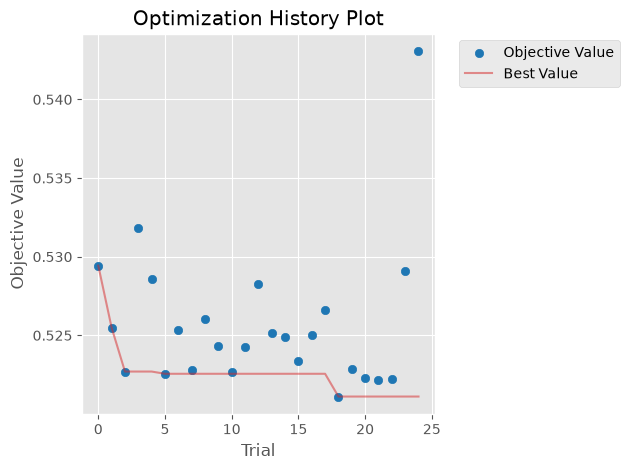

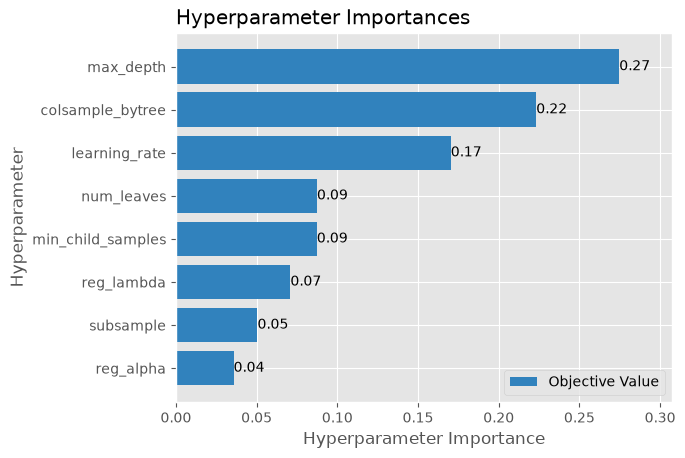

In [39]:
### 12.4 — modèle final, Registry v3 & artefacts
import tempfile, os

final_params = dict(best.params) | {
    'objective': 'binary', 'n_estimators': 3000, 'subsample_freq': 1,
    'random_state': 42, 'n_jobs': -1, 'verbosity': -1,
}

lgb_tuned = lgb.LGBMClassifier(**final_params)
t0 = time.perf_counter()
lgb_tuned.fit(
    X_tr_fs_enc, y_tr_fs,
    eval_X=X_va_fs_enc, eval_y=y_va_fs,
    categorical_feature=list(range(len(cat_cols_fs))),
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
fit_seconds = time.perf_counter() - t0

y_proba_tr_t = lgb_tuned.predict_proba(X_tr_fs_enc)[:, 1]
y_proba_va_t = lgb_tuned.predict_proba(X_va_fs_enc)[:, 1]
thr_t, _ = optimal_threshold(y_tr_fs, y_proba_tr_t)
auc_t = roc_auc_score(y_va_fs, y_proba_va_t)
ap_t = average_precision_score(y_va_fs, y_proba_va_t)
cost_t = business_cost(y_va_fs, y_proba_va_t, thr_t)

print(f'=== Validation — LightGBM tuned ({X_tr_fs.shape[1]} features) ===')
print(f'best iteration : {lgb_tuned.best_iteration_:,}')
print(f'ROC-AUC : {auc_t:.4f} | PR-AUC : {ap_t:.4f} | seuil : {thr_t:.4f}')
print(f'Coût/client : {cost_t:.4f}   (réf. untuned 61 feat : 0.5229)')

from mlflow.models.signature import infer_signature
signature_t = infer_signature(X_tr_fs_enc, y_proba_tr_t)

with tempfile.TemporaryDirectory() as tmpdir:
    fig1 = plot_optimization_history(study)
    fig1.figure.savefig(os.path.join(tmpdir, 'optuna_history.png'), dpi=120, bbox_inches='tight')
    fig2 = plot_param_importances(study)
    fig2.figure.savefig(os.path.join(tmpdir, 'optuna_param_importances.png'), dpi=120, bbox_inches='tight')

    with mlflow.start_run(run_name='tuning_optuna') as run:
        mlflow.log_params(final_params | {'n_trials': N_TRIALS_OPTUNA, 'cv': 5,
                                          'fn_cost': FN_COST, 'fp_cost': FP_COST})
        mlflow.set_tags({'stage': 'tuning', 'sampler': 'TPE',
                         'custom_metric': 'business_cost_fn10_fp1', 'feature_set': 'boruta_61'})
        mlflow.log_metrics({
            'cv_cost_best': best.value,
            'cv_roc_auc_best': best.user_attrs['mean_val_roc_auc'],
            'cv_roc_auc_std': best.user_attrs['std_val_roc_auc'],
            'val_roc_auc': auc_t, 'val_pr_auc': ap_t,
            'val_best_threshold': thr_t,
            'val_cost_per_client_best': cost_t,
            'best_iteration': int(lgb_tuned.best_iteration_),
            'tuning_seconds': tuning_seconds, 'fit_seconds': fit_seconds,
        })
        mlflow.log_artifacts(tmpdir)
        # Registry v3 : signature + input example + types de confiance
        mlflow.lightgbm.log_model(
            lgb_tuned,
            name='lightgbm_tuned',
            signature=signature_t,
            input_example=X_tr_fs_enc[:5],
            registered_model_name='home-credit-lightgbm',
            skops_trusted_types=[
                'numpy.dtype', 'collections.OrderedDict',
                'lightgbm.basic.Booster', 'lightgbm.sklearn.LGBMClassifier',
            ],
        )
        print('Run tuning_optuna :', run.info.run_id)
        print('Modèle enregistré : home-credit-lightgbm v3 (tuned)')

### 12.5 — bilan du tuning

- **Objectif aligné métier** : Optuna minimise directement le **coût métier moyen en CV 5-fold**
  (seuil optimisé par fold sur l'entraînement du fold — aucune fuite), pas un proxy AUC.
- **Artefacts** : historique d'optimisation et importances des hyperparamètres (PNG) logués ;
  params/métriques dans la run `tuning_optuna`.
- **Registry** : `home-credit-lightgbm` **v3** — le meilleur modèle, avec signature et seuil optimal figé.
- **Étape restante** : évaluation **une seule fois** sur `application_test.csv` (toujours inviolé) —
  charge de préparation via `preprocessing_bundle.joblib` + sélection Boruta + encodage figés.